# Stage 4.3A — Continuous Variable Pre-bin Diagnostics

Train-only, target-independent candidate pre-bins for exactly 17 continuous predictors. This Notebook does not create final bins, perform automatic merging, select variables, model outcomes, or inspect Holdout predictor/target behavior. It stops at the mandatory Architect/user Human Checkpoint.


In [1]:
from pathlib import Path
import hashlib
import inspect
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
TARGET="default.payment.next.month"; ID_COL="ID"; RANDOM_STATE=42; TEST_SIZE=.20
EXPECTED_TRAIN_HASH="bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857"
EXPECTED_TEST_HASH="d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"
AGE_LIMIT=["AGE","LIMIT_BAL"]
BILL_VARIABLES=[f"BILL_AMT{i}" for i in range(1,7)]
PAY_AMT_VARIABLES=[f"PAY_AMT{i}" for i in range(1,7)]
UTILIZATION_VARIABLES=["current_utilization","avg_utilization","max_utilization"]
CONTINUOUS_VARIABLES=AGE_LIMIT+BILL_VARIABLES+PAY_AMT_VARIABLES+UTILIZATION_VARIABLES
assert len(CONTINUOUS_VARIABLES)==17 and len(set(CONTINUOUS_VARIABLES))==17

def locate_root():
    for candidate in (Path.cwd().resolve(),*Path.cwd().resolve().parents):
        if (candidate/"data/raw/UCI_Credit_Card.csv").is_file(): return candidate
    raise FileNotFoundError("Formal raw CSV not found")
def stable_id_hash(values):
    return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()
project_root=locate_root(); data_path=project_root/"data/raw/UCI_Credit_Card.csv"
print("Python:",sys.executable,sys.version.split()[0]); print("Project root:",project_root); print("Continuous scope:",len(CONTINUOUS_VARIABLES),CONTINUOUS_VARIABLES)


Matplotlib is building the font cache; this may take a moment.


Python: /Users/yu/2.工作/Risk Analysis Project/.venv/bin/python 3.9.6
Project root: /Users/yu/2.工作/Risk Analysis Project
Continuous scope: 17 ['AGE', 'LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'current_utilization', 'avg_utilization', 'max_utilization']


## 1. Raw load, frozen split replay, and immediate Holdout sealing

Holdout participates only in row/ID/hash assertions. No Test predictor distribution, range, quantile, state occupancy, target rate, WOE, IV, or risk relationship is inspected.


In [2]:
raw_df=pd.read_csv(data_path); assert raw_df.shape==(30000,25) and raw_df[ID_COL].is_unique
train_raw,sealed_test=train_test_split(raw_df,test_size=TEST_SIZE,random_state=RANDOM_STATE,stratify=raw_df[TARGET])
train_ids=set(train_raw[ID_COL].astype(int)); test_ids=set(sealed_test[ID_COL].astype(int)); full_ids=set(raw_df[ID_COL].astype(int))
train_hash=stable_id_hash(train_ids); test_hash=stable_id_hash(test_ids)
assert len(train_raw)==24000 and len(sealed_test)==6000 and train_ids.isdisjoint(test_ids) and train_ids|test_ids==full_ids
assert train_hash==EXPECTED_TRAIN_HASH and test_hash==EXPECTED_TEST_HASH
split_evidence=pd.DataFrame({"Actual":[30000,24000,6000,0,True,train_hash,test_hash]},index=["Raw rows","Train rows","Test rows","ID overlap","Full coverage","Train ID SHA-256","Test ID SHA-256"]); display(split_evidence)
train_original=train_raw.copy(deep=True)
del sealed_test,test_ids,full_ids,raw_df
TEST_SEAL_STATUS="SEALED — Test deleted after technical row/ID/hash assertions"
print(TEST_SEAL_STATUS)


,Actual
Raw rows,30000
Train rows,24000
Test rows,6000
ID overlap,0
Full coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — Test deleted after technical row/ID/hash assertions


## 2. Reproduce frozen Stage 3 utilization features

Only the BILL matrix is zero-floored inside utilization formulas. Raw BILL values remain unchanged; values above 1 are retained without clipping, capping, or winsorization.


In [3]:
train_work=train_raw.copy(deep=True); raw_bills_before=train_work[BILL_VARIABLES].copy(deep=True); ids_before=train_work[ID_COL].copy(); target_before=train_work[TARGET].copy(); index_before=train_work.index.copy()
assert (train_work["LIMIT_BAL"]>0).all()
nonnegative_bills=train_work[BILL_VARIABLES].clip(lower=0)
train_work["current_utilization"]=nonnegative_bills["BILL_AMT1"]/train_work["LIMIT_BAL"]
train_work["avg_utilization"]=nonnegative_bills.mean(axis=1)/train_work["LIMIT_BAL"]
train_work["max_utilization"]=nonnegative_bills.max(axis=1)/train_work["LIMIT_BAL"]
pd.testing.assert_frame_equal(train_work[BILL_VARIABLES],raw_bills_before,check_exact=True)
assert len(train_work)==24000 and train_work.index.equals(index_before) and train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
assert train_work[UTILIZATION_VARIABLES].notna().all().all() and np.isfinite(train_work[UTILIZATION_VARIABLES].to_numpy()).all()
assert (train_work[UTILIZATION_VARIABLES]>=0).all().all() and (train_work["current_utilization"]<=train_work["max_utilization"]+1e-15).all() and (train_work["avg_utilization"]<=train_work["max_utilization"]+1e-15).all()
assert (train_work[UTILIZATION_VARIABLES]>1).any().all()
TOTAL_GOOD=int((train_work[TARGET]==0).sum()); TOTAL_BAD=int((train_work[TARGET]==1).sum()); assert (TOTAL_GOOD,TOTAL_BAD)==(18691,5309)
display(pd.DataFrame({"Result":["PASS — 24,000 rows; ID/order/target unchanged","PASS — six raw BILL columns unchanged","PASS — frozen zero-floor formulas reproduced","PASS — finite, nonnegative, >1 retained","PASS — no clipping/capping/winsorization"]},index=["Row integrity","Raw BILL integrity","Utilization formulas","Domain","Transform exclusions"]))


,Result
Row integrity,"PASS — 24,000 rows; ID/order/target unchanged"
Raw BILL integrity,PASS — six raw BILL columns unchanged
Utilization formulas,PASS — frozen zero-floor formulas reproduced
Domain,"PASS — finite, nonnegative, >1 retained"
Transform exclusions,PASS — no clipping/capping/winsorization


## 3. Target-independent quantile pre-bin and diagnostic helpers

`quantile_edges` accepts predictor values and a requested count only. It uses Train predictor quantiles with `higher` interpolation, explicitly collapses duplicate boundaries, keeps identical values together, and never receives target/WOE/IV. Target is joined only after assignments are frozen.


In [4]:
def quantile_edges(predictor,requested_bins):
    s=pd.Series(predictor).dropna(); assert len(s)>0 and requested_bins>=1
    probabilities=np.linspace(0,1,requested_bins+1)
    raw=s.quantile(probabilities,interpolation="higher").to_numpy(dtype=float)
    edges=np.unique(raw)
    if len(edges)<2: raise ValueError("Need at least two distinct predictor boundaries")
    return edges,{"requested_quantile_bins":requested_bins,"raw_edge_count":len(raw),"unique_edge_count":len(edges),"duplicate_boundary_reduction":len(raw)-len(edges)}
assert list(inspect.signature(quantile_edges).parameters)==["predictor","requested_bins"]

def fmt_num(v):
    if np.isneginf(v): return "-∞"
    if np.isposinf(v): return "+∞"
    return f"{float(v):.12g}"
def numeric_assign(series,edges,prefix="Q"):
    values=series.to_numpy(dtype=float); interior=edges[1:-1]; idx=np.searchsorted(interior,values,side="left")
    assignments=pd.Series([f"{prefix}{i+1:02d}" for i in idx],index=series.index,dtype="object")
    defs=[]
    for i,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
        defs.append({"Pre-bin ID":f"{prefix}{i+1:02d}","Numeric interval / candidate state":f"[{fmt_num(lo)}, {fmt_num(hi)}]" if i==0 else f"({fmt_num(lo)}, {fmt_num(hi)}]","Lower bound":float(lo),"Upper bound":float(hi)})
    return assignments,defs

def make_prebins(variable,kind,requested_quantile_bins):
    s=train_work[variable]; assert s.notna().all(); assignments=pd.Series(index=s.index,dtype="object"); defs=[]
    if kind=="ordinary":
        edges,meta=quantile_edges(s,requested_quantile_bins); assignments,defs=numeric_assign(s,edges)
    elif kind=="bill":
        neg=s<0; zero=s==0; pos=s>0; assert neg.any() and zero.any() and pos.any()
        assignments.loc[neg]="S01"; assignments.loc[zero]="S02"
        defs=[{"Pre-bin ID":"S01","Numeric interval / candidate state":"Negative (<0)","Lower bound":-np.inf,"Upper bound":0.0},{"Pre-bin ID":"S02","Numeric interval / candidate state":"Zero (=0)","Lower bound":0.0,"Upper bound":0.0}]
        edges,meta=quantile_edges(s.loc[pos],requested_quantile_bins); a,d=numeric_assign(s.loc[pos],edges,"P"); assignments.loc[pos]=a; defs+=d
    elif kind=="payment":
        assert (s>=0).all(); zero=s==0; pos=s>0; assert zero.any() and pos.any(); assignments.loc[zero]="S01"
        defs=[{"Pre-bin ID":"S01","Numeric interval / candidate state":"Zero (=0)","Lower bound":0.0,"Upper bound":0.0}]
        edges,meta=quantile_edges(s.loc[pos],requested_quantile_bins); a,d=numeric_assign(s.loc[pos],edges,"P"); assignments.loc[pos]=a; defs+=d
    elif kind=="utilization":
        zero=s==0; interior=(s>0)&(s<=1); above=s>1; assert zero.any() and interior.any() and above.any(); assignments.loc[zero]="S01"; assignments.loc[above]="S99"
        defs=[{"Pre-bin ID":"S01","Numeric interval / candidate state":"Zero (=0)","Lower bound":0.0,"Upper bound":0.0}]
        edges,meta=quantile_edges(s.loc[interior],requested_quantile_bins); a,d=numeric_assign(s.loc[interior],edges,"I"); assignments.loc[interior]=a; defs+=d
        defs+=[{"Pre-bin ID":"S99","Numeric interval / candidate state":">1","Lower bound":1.0,"Upper bound":np.inf}]
    else: raise ValueError(kind)
    assert assignments.notna().all() and len(defs)==assignments.nunique()
    meta.update({"variable":variable,"kind":kind,"requested_total_bins":requested_quantile_bins+(2 if kind in ("bill","utilization") else 1 if kind=="payment" else 0),"actual_candidate_bins":len(defs),"unique_value_count":int(s.nunique()),"special_states":{"ordinary":"none","bill":"<0; =0","payment":"=0","utilization":"=0; >1"}[kind]})
    return assignments,pd.DataFrame(defs),meta

def diagnostic_table(assignments,definitions):
    g=pd.DataFrame({"Pre-bin ID":assignments,TARGET:train_work[TARGET]}).groupby("Pre-bin ID",sort=False)[TARGET].agg(Count="size",Bad="sum")
    g["Good"]=g.Count-g.Bad; table=definitions.merge(g.reset_index(),on="Pre-bin ID",how="left",validate="one_to_one")
    table["% Train"]=table.Count/24000; table["Default Rate"]=table.Bad/table.Count; table["Dist Good"]=table.Good/TOTAL_GOOD; table["Dist Bad"]=table.Bad/TOTAL_BAD
    with np.errstate(divide="ignore",invalid="ignore"):
        table["WOE"]=np.log(table["Dist Good"]/table["Dist Bad"]); table["IV Contribution"]=(table["Dist Good"]-table["Dist Bad"])*table.WOE
    table["Zero-event flag"]=np.select([table.Good==0,table.Bad==0],["Good=0 — Human review","Bad=0 — Human review"],default="None")
    table=table[["Pre-bin ID","Numeric interval / candidate state","Lower bound","Upper bound","Count","% Train","Good","Bad","Default Rate","Dist Good","Dist Bad","WOE","IV Contribution","Zero-event flag"]]
    assert (table.Count==table.Good+table.Bad).all() and int(table.Count.sum())==24000 and int(table.Good.sum())==TOTAL_GOOD and int(table.Bad.sum())==TOTAL_BAD
    assert np.isclose(table["% Train"].sum(),1) and np.isclose(table["Dist Good"].sum(),1) and np.isclose(table["Dist Bad"].sum(),1)
    return table

prebin_assignments={}; prebin_tables={}; prebin_metadata={}; prebin_iv_totals={}; figure_ids=[]
def render_prebin_figure(variable,table,figure_id):
    labels=table["Pre-bin ID"].tolist(); x=np.arange(len(labels)); fig,axes=plt.subplots(2,1,figsize=(11.5,5.8),sharex=True,gridspec_kw={"height_ratios":[2,1.25]})
    finite=table["Default Rate"].fillna(0); axes[0].bar(x,finite,color="#4472C4"); axes[0].set_ylabel("Default Rate"); axes[0].grid(axis="y",alpha=.25)
    axes[1].bar(x,table.Count,color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Ordered candidate pre-bin ID"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels,rotation=70)
    fig.suptitle(f"{figure_id} — {variable}: candidate pre-bin risk and support"); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append(figure_id)
def run_variable(variable,kind,requested_quantile_bins,figure_id):
    a,d,m=make_prebins(variable,kind,requested_quantile_bins); a2,d2,m2=make_prebins(variable,kind,requested_quantile_bins)
    assert a.equals(a2); pd.testing.assert_frame_equal(d,d2); assert m==m2
    table=diagnostic_table(a,d); prebin_assignments[variable]=a; prebin_tables[variable]=table; prebin_metadata[variable]=m; prebin_iv_totals[variable]=float(table["IV Contribution"].sum())
    smallest=table.loc[table.Count.idxmin()]; low=table.loc[table["Default Rate"].idxmin()]; high=table.loc[table["Default Rate"].idxmax()]
    print("Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?")
    print("Why it matters: Human review needs target-independent detail before any supervised final grouping.")
    print(f"Observed factual pattern: {m['actual_candidate_bins']} bins; Default Rate spans {low['Default Rate']:.2%} to {high['Default Rate']:.2%}; smallest support {int(smallest.Count):,} ({smallest['% Train']:.3%}); duplicate-edge reduction {m['duplicate_boundary_reduction']}.")
    print("Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.")
    display(table); print(f"Raw pre-bin total IV: {prebin_iv_totals[variable]:.12f} — diagnostic only; no variable-selection decision")
    render_prebin_figure(variable,table,figure_id)
print("Helpers ready. Boundary construction signature excludes target; no jitter/noise/rounding/target-guided search.")


Helpers ready. Boundary construction signature excludes target; no jitter/noise/rounding/target-guided search.


## CBIN-01 — AGE pre-bin diagnostics

Quantile-style candidates respect whole observed ages and ties; no jitter and no final age groups. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 18.79% to 28.30%; smallest support 649 (2.704%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,Q01,"[21, 23]",21.000000,23.000000,1265,0.052708,907,358,0.283004,0.048526,0.067433,-0.329029,0.006221,None
1,Q02,"(23, 25]",23.000000,25.000000,1839,0.076625,1361,478,0.259924,0.072816,0.090036,-0.212274,0.003655,None
2,Q03,"(25, 26]",25.000000,26.000000,999,0.041625,804,195,0.195195,0.043015,0.036730,0.157961,0.000993,None
3,Q04,"(26, 27]",26.000000,27.000000,1194,0.049750,941,253,0.211893,0.050345,0.047655,0.054915,0.000148,None
4,Q05,"(27, 28]",27.000000,28.000000,1129,0.047042,892,237,0.209920,0.047724,0.044641,0.066767,0.000206,None
5,Q06,"(28, 29]",28.000000,29.000000,1280,0.053333,1031,249,0.194531,0.055160,0.046901,0.162193,0.001340,None
6,Q07,"(29, 30]",29.000000,30.000000,1126,0.046917,904,222,0.197158,0.048366,0.041816,0.145513,0.000953,None
7,Q08,"(30, 31]",30.000000,31.000000,995,0.041458,808,187,0.187940,0.043229,0.035223,0.204815,0.001640,None
8,Q09,"(31, 33]",31.000000,33.000000,1874,0.078083,1512,362,0.193170,0.080895,0.068186,0.170906,0.002172,None
9,Q10,"(33, 34]",33.000000,34.000000,936,0.039000,750,186,0.198718,0.040126,0.035035,0.135688,0.000691,None


Raw pre-bin total IV: 0.023244905817 — diagnostic only; no variable-selection decision


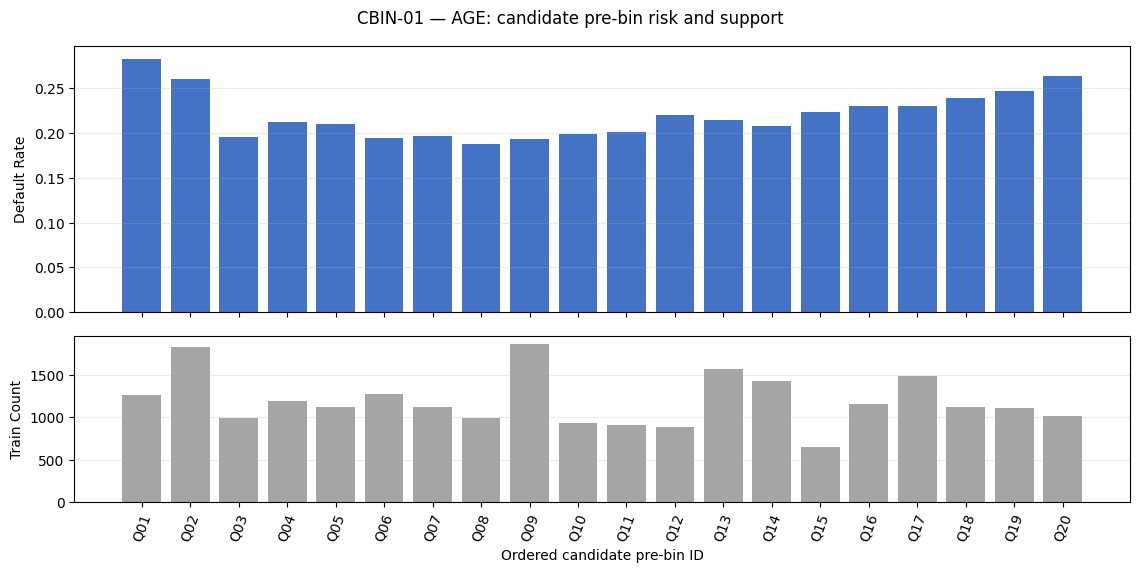

In [5]:
run_variable("AGE","ordinary",20,"CBIN-01")


## CBIN-02 — LIMIT_BAL pre-bin diagnostics

Actual Train quantile boundaries are preserved without nice-number adjustment. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 18 bins; Default Rate spans 10.09% to 36.85%; smallest support 600 (2.500%); duplicate-edge reduction 2.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,Q01,"[10000, 20000]",10000.000000,20000.000000,1989,0.082875,1256,733,0.368527,0.067198,0.138067,-0.720097,0.051033,None
1,Q02,"(20000, 30000]",20000.000000,30000.000000,1267,0.052792,811,456,0.359905,0.043390,0.085892,-0.682863,0.029023,None
2,Q03,"(30000, 50000]",30000.000000,50000.000000,2890,0.120417,2102,788,0.272664,0.112461,0.148427,-0.277492,0.009980,None
3,Q04,"(50000, 70000]",50000.000000,70000.000000,1231,0.051292,873,358,0.290820,0.046707,0.067433,-0.367236,0.007611,None
4,Q05,"(70000, 80000]",70000.000000,80000.000000,1229,0.051208,954,275,0.223759,0.051041,0.051799,-0.014746,0.000011,None
5,Q06,"(80000, 100000]",80000.000000,100000.000000,1359,0.056625,1002,357,0.262693,0.053609,0.067244,-0.226621,0.003090,None
6,Q07,"(100000, 120000]",100000.000000,120000.000000,1039,0.043292,794,245,0.235804,0.042480,0.046148,-0.082813,0.000304,None
7,Q08,"(120000, 140000]",120000.000000,140000.000000,1209,0.050375,935,274,0.226634,0.050024,0.051610,-0.031220,0.000050,None
8,Q09,"(140000, 160000]",140000.000000,160000.000000,1455,0.060625,1191,264,0.181443,0.063721,0.049727,0.247961,0.003470,None
9,Q10,"(160000, 180000]",160000.000000,180000.000000,1219,0.050792,1020,199,0.163249,0.054572,0.037484,0.375614,0.006419,None


Raw pre-bin total IV: 0.201675446880 — diagnostic only; no variable-selection decision


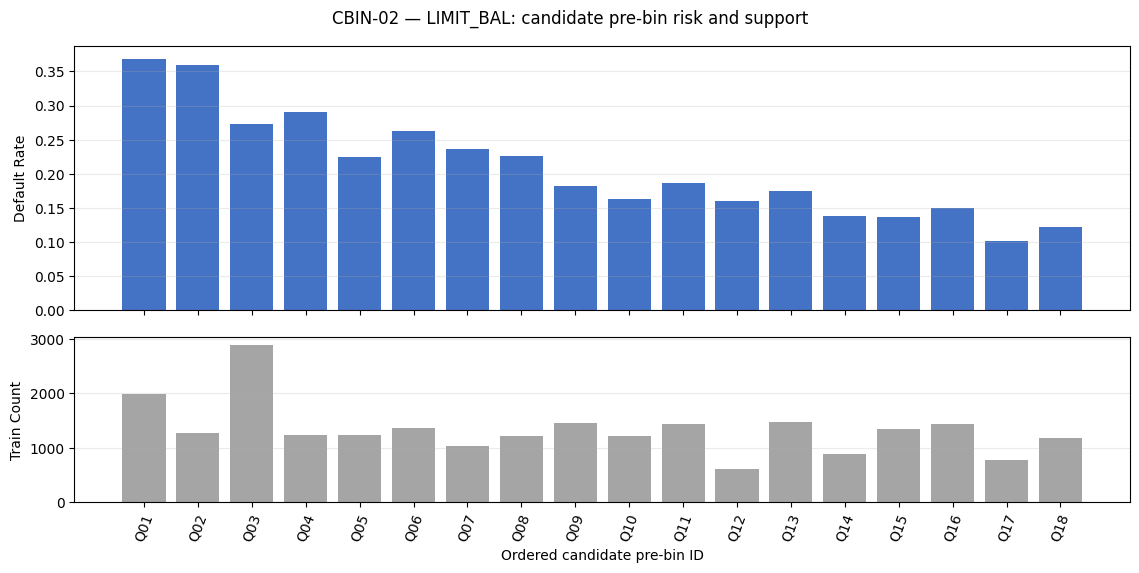

In [6]:
run_variable("LIMIT_BAL","ordinary",20,"CBIN-02")


## CBIN-03 — BILL_AMT1 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 17.52% to 27.09%; smallest support 468 (1.950%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,468,0.019500,386,82,0.175214,0.020652,0.015445,0.290479,0.001512,None
1,S02,Zero (=0),0.000000,0.000000,1612,0.067167,1178,434,0.269231,0.063025,0.081748,-0.260110,0.004870,None
2,P01,"[1, 632]",1.000000,632.000000,1226,0.051083,948,278,0.226754,0.050720,0.052364,-0.031905,0.000052,None
3,P02,"(632, 1547]",632.000000,1547.000000,1211,0.050458,955,256,0.211396,0.051094,0.048220,0.057895,0.000166,None
4,P03,"(1547, 3088]",1547.000000,3088.000000,1219,0.050792,954,265,0.217391,0.051041,0.049915,0.022295,0.000025,None
5,P04,"(3088, 5496]",3088.000000,5496.000000,1216,0.050667,998,218,0.179276,0.053395,0.041062,0.262620,0.003239,None
6,P05,"(5496, 8541]",5496.000000,8541.000000,1218,0.050750,941,277,0.227422,0.050345,0.052176,-0.035713,0.000065,None
7,P06,"(8541, 12547]",8541.000000,12547.000000,1218,0.050750,961,257,0.211002,0.051415,0.048408,0.060260,0.000181,None
8,P07,"(12547, 17100]",12547.000000,17100.000000,1218,0.050750,888,330,0.270936,0.047509,0.062159,-0.268760,0.003937,None
9,P08,"(17100, 21353]",17100.000000,21353.000000,1217,0.050708,912,305,0.250616,0.048794,0.057450,-0.163310,0.001414,None


Raw pre-bin total IV: 0.024475436284 — diagnostic only; no variable-selection decision


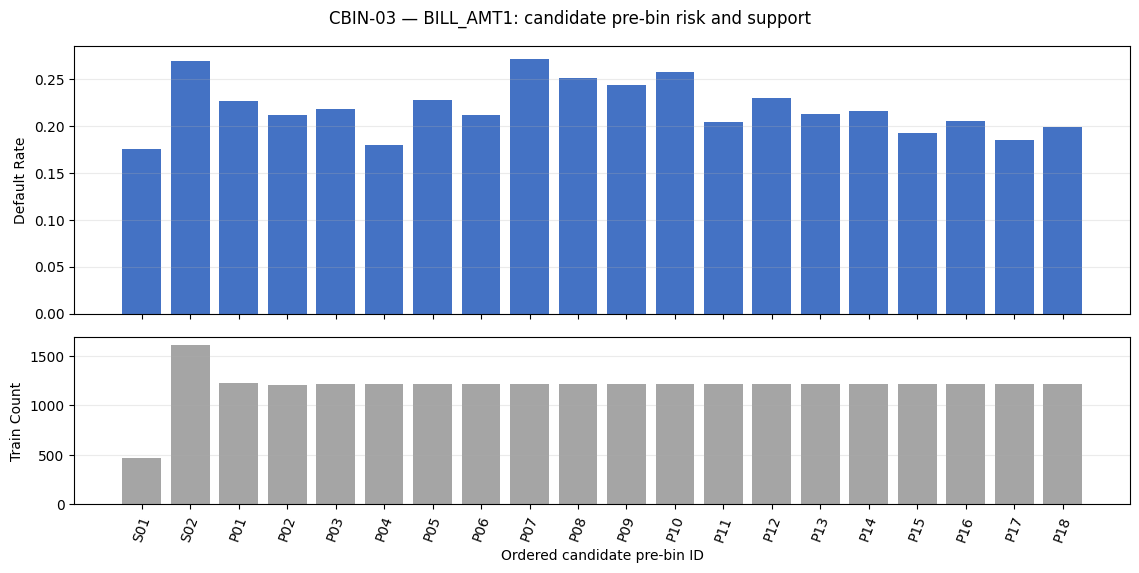

In [7]:
run_variable("BILL_AMT1","bill",18,"CBIN-03")


## CBIN-04 — BILL_AMT2 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 17.24% to 26.80%; smallest support 522 (2.175%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,522,0.021750,432,90,0.172414,0.023113,0.016952,0.309977,0.001910,None
1,S02,Zero (=0),0.000000,0.000000,1986,0.082750,1501,485,0.244209,0.080306,0.091354,-0.128901,0.001424,None
2,P01,"[3, 598]",3.000000,598.000000,1197,0.049875,931,266,0.222222,0.049810,0.050104,-0.005876,0.000002,None
3,P02,"(598, 1572]",598.000000,1572.000000,1193,0.049708,945,248,0.207879,0.050559,0.046713,0.079118,0.000304,None
4,P03,"(1572, 3160]",1572.000000,3160.000000,1193,0.049708,930,263,0.220453,0.049757,0.049539,0.004392,0.000001,None
5,P04,"(3160, 5714]",3160.000000,5714.000000,1194,0.049750,973,221,0.185092,0.052057,0.041627,0.223583,0.002332,None
6,P05,"(5714, 8958]",5714.000000,8958.000000,1195,0.049792,949,246,0.205858,0.050773,0.046336,0.091439,0.000406,None
7,P06,"(8958, 13047]",8958.000000,13047.000000,1193,0.049708,917,276,0.231350,0.049061,0.051987,-0.057932,0.000170,None
8,P07,"(13047, 17472]",13047.000000,17472.000000,1194,0.049750,874,320,0.268007,0.046760,0.060275,-0.253879,0.003431,None
9,P08,"(17472, 21470]",17472.000000,21470.000000,1194,0.049750,884,310,0.259631,0.047295,0.058391,-0.210754,0.002339,None


Raw pre-bin total IV: 0.022332944819 — diagnostic only; no variable-selection decision


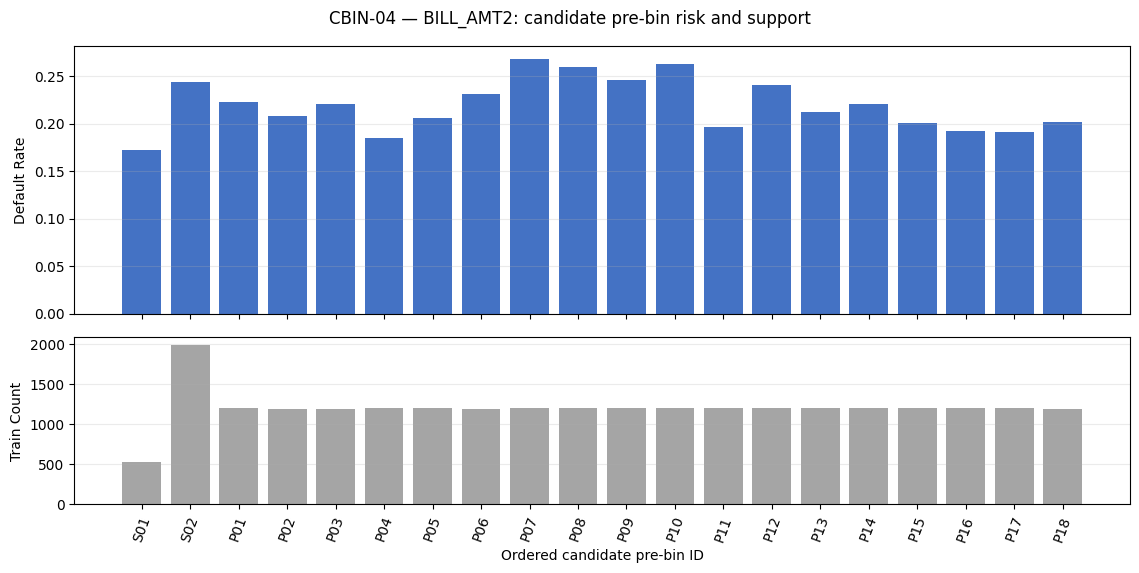

In [8]:
run_variable("BILL_AMT2","bill",18,"CBIN-04")


## CBIN-05 — BILL_AMT3 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 17.77% to 26.49%; smallest support 515 (2.146%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,515,0.021458,419,96,0.186408,0.022417,0.018083,0.214884,0.000931,None
1,S02,Zero (=0),0.000000,0.000000,2308,0.096167,1759,549,0.237868,0.094109,0.103409,-0.094236,0.000876,None
2,P01,"[1, 600]",1.000000,600.000000,1185,0.049375,917,268,0.226160,0.049061,0.050480,-0.028518,0.000040,None
3,P02,"(600, 1580]",600.000000,1580.000000,1169,0.048708,926,243,0.207870,0.049543,0.045771,0.079174,0.000299,None
4,P03,"(1580, 3323]",1580.000000,3323.000000,1177,0.049042,925,252,0.214104,0.049489,0.047467,0.041726,0.000084,None
5,P04,"(3323, 6057]",3323.000000,6057.000000,1176,0.049000,967,209,0.177721,0.051736,0.039367,0.273226,0.003380,None
6,P05,"(6057, 9316]",6057.000000,9316.000000,1177,0.049042,927,250,0.212404,0.049596,0.047090,0.051854,0.000130,None
7,P06,"(9316, 13403]",9316.000000,13403.000000,1176,0.049000,898,278,0.236395,0.048045,0.052364,-0.086090,0.000372,None
8,P07,"(13403, 17697]",13403.000000,17697.000000,1177,0.049042,890,287,0.243840,0.047616,0.054059,-0.126899,0.000818,None
9,P08,"(17697, 20858]",17697.000000,20858.000000,1176,0.049000,869,307,0.261054,0.046493,0.057826,-0.218143,0.002472,None


Raw pre-bin total IV: 0.017565383524 — diagnostic only; no variable-selection decision


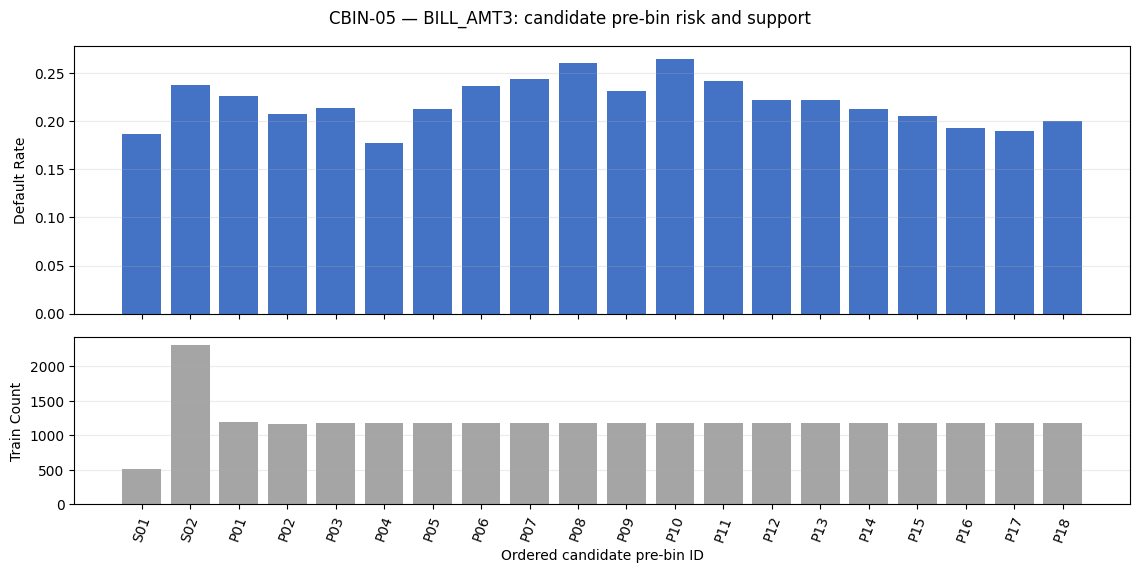

In [9]:
run_variable("BILL_AMT3","bill",18,"CBIN-05")


## CBIN-06 — BILL_AMT4 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 17.17% to 28.49%; smallest support 530 (2.208%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,530,0.022083,439,91,0.171698,0.023487,0.017141,0.315001,0.001999,None
1,S02,Zero (=0),0.000000,0.000000,2555,0.106458,1941,614,0.240313,0.103847,0.115653,-0.107675,0.001271,None
2,P01,"[2, 632]",2.000000,632.000000,1166,0.048583,881,285,0.244425,0.047135,0.053682,-0.130070,0.000852,None
3,P02,"(632, 1560]",632.000000,1560.000000,1161,0.048375,917,244,0.210164,0.049061,0.045960,0.065301,0.000203,None
4,P03,"(1560, 3220]",1560.000000,3220.000000,1160,0.048333,932,228,0.196552,0.049864,0.042946,0.149349,0.001033,None
5,P04,"(3220, 6106]",3220.000000,6106.000000,1162,0.048417,962,200,0.172117,0.051469,0.037672,0.312058,0.004305,None
6,P05,"(6106, 9221]",6106.000000,9221.000000,1162,0.048417,924,238,0.204819,0.049436,0.044830,0.097803,0.000450,None
7,P06,"(9221, 12985]",9221.000000,12985.000000,1162,0.048417,908,254,0.218589,0.048580,0.047843,0.015271,0.000011,None
8,P07,"(12985, 17087]",12985.000000,17087.000000,1162,0.048417,897,265,0.228055,0.047991,0.049915,-0.039313,0.000076,None
9,P08,"(17087, 19772]",17087.000000,19772.000000,1162,0.048417,831,331,0.284854,0.044460,0.062347,-0.338127,0.006048,None


Raw pre-bin total IV: 0.023339663152 — diagnostic only; no variable-selection decision


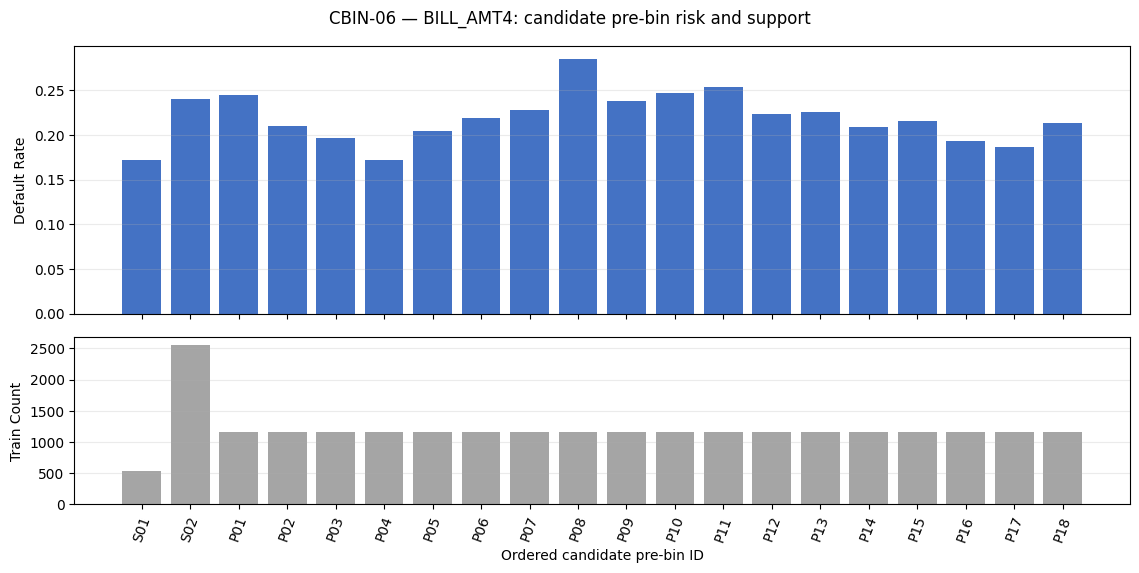

In [10]:
run_variable("BILL_AMT4","bill",18,"CBIN-06")


## CBIN-07 — BILL_AMT5 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 15.34% to 26.68%; smallest support 524 (2.183%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,524,0.021833,421,103,0.196565,0.022524,0.019401,0.149265,0.000466,None
1,S02,Zero (=0),0.000000,0.000000,2828,0.117833,2138,690,0.243989,0.114387,0.129968,-0.127704,0.001990,None
2,P01,"[1, 572]",1.000000,572.000000,1149,0.047875,893,256,0.222802,0.047777,0.048220,-0.009229,0.000004,None
3,P02,"(572, 1368]",572.000000,1368.000000,1147,0.047792,908,239,0.208370,0.048580,0.045018,0.076142,0.000271,None
4,P03,"(1368, 2806]",1368.000000,2806.000000,1147,0.047792,918,229,0.199651,0.049115,0.043134,0.129837,0.000776,None
5,P04,"(2806, 5474]",2806.000000,5474.000000,1147,0.047792,971,176,0.153444,0.051950,0.033151,0.449204,0.008445,None
6,P05,"(5474, 8657]",5474.000000,8657.000000,1147,0.047792,933,214,0.186574,0.049917,0.040309,0.213791,0.002054,None
7,P06,"(8657, 11875]",8657.000000,11875.000000,1148,0.047833,898,250,0.217770,0.048045,0.047090,0.020071,0.000019,None
8,P07,"(11875, 16179]",11875.000000,16179.000000,1147,0.047792,862,285,0.248474,0.046118,0.053682,-0.151873,0.001149,None
9,P08,"(16179, 19182]",16179.000000,19182.000000,1146,0.047750,847,299,0.260908,0.045316,0.056319,-0.217382,0.002392,None


Raw pre-bin total IV: 0.028634371616 — diagnostic only; no variable-selection decision


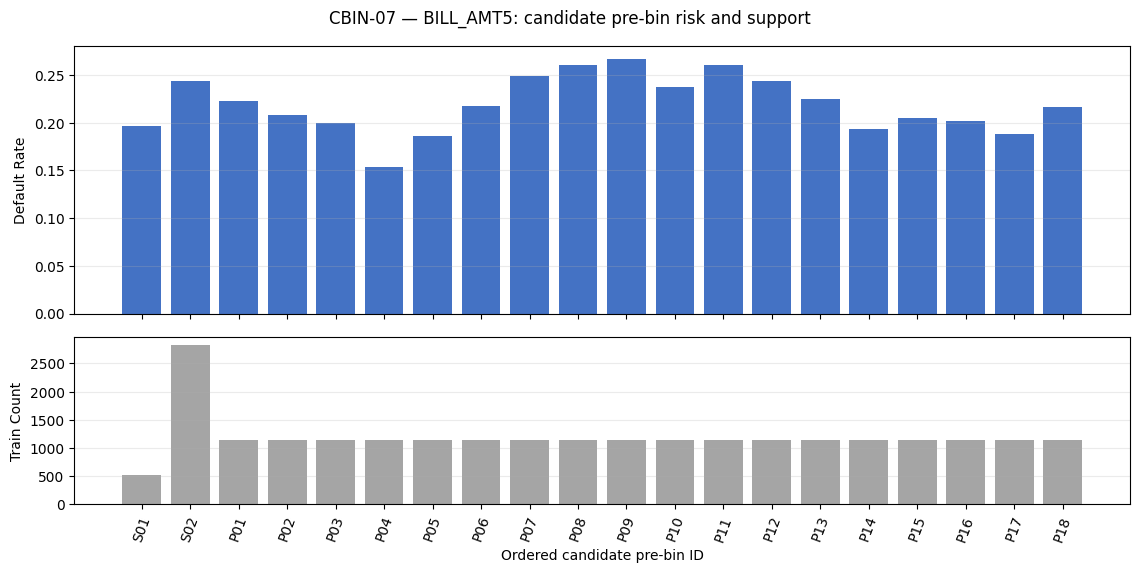

In [11]:
run_variable("BILL_AMT5","bill",18,"CBIN-07")


## CBIN-08 — BILL_AMT6 pre-bin diagnostics

Negative and zero stay separately visible; positive values alone receive predictor-only quantiles. Negative BILL is only a numerically distinct/unusual observed state; no business semantics are invented. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 15.30% to 27.43%; smallest support 556 (2.317%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Negative (<0),-inf,0.000000,556,0.023167,453,103,0.185252,0.024236,0.019401,0.222525,0.001076,None
1,S02,Zero (=0),0.000000,0.000000,3223,0.134292,2474,749,0.232392,0.132363,0.141081,-0.063786,0.000556,None
2,P01,"[1, 514]",1.000000,514.000000,1125,0.046875,878,247,0.219556,0.046974,0.046525,0.009620,0.000004,None
3,P02,"(514, 1248]",514.000000,1248.000000,1123,0.046792,904,219,0.195013,0.048366,0.041251,0.159119,0.001132,None
4,P03,"(1248, 2566]",1248.000000,2566.000000,1123,0.046792,886,237,0.211042,0.047402,0.044641,0.060018,0.000166,None
5,P04,"(2566, 5034]",2566.000000,5034.000000,1124,0.046833,952,172,0.153025,0.050934,0.032398,0.452432,0.008386,None
6,P05,"(5034, 8175]",5034.000000,8175.000000,1123,0.046792,908,215,0.191451,0.048580,0.040497,0.181968,0.001471,None
7,P06,"(8175, 11166]",8175.000000,11166.000000,1123,0.046792,871,252,0.224399,0.046600,0.047467,-0.018426,0.000016,None
8,P07,"(11166, 15725]",11166.000000,15725.000000,1124,0.046833,863,261,0.232206,0.046172,0.049162,-0.062744,0.000188,None
9,P08,"(15725, 19042]",15725.000000,19042.000000,1123,0.046792,823,300,0.267142,0.044032,0.056508,-0.249465,0.003112,None


Raw pre-bin total IV: 0.029269001784 — diagnostic only; no variable-selection decision


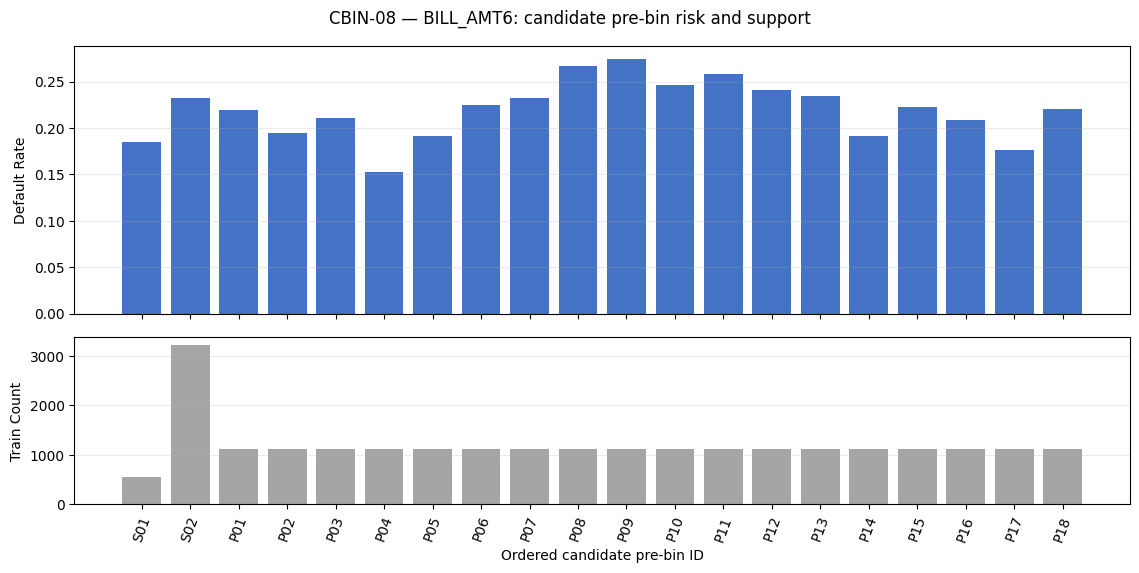

In [12]:
run_variable("BILL_AMT6","bill",18,"CBIN-08")


## CBIN-09 — PAY_AMT1 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 9.21% to 35.81%; smallest support 768 (3.200%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,4180,0.174167,2683,1497,0.358134,0.143545,0.281974,-0.675166,0.093463,None
1,P01,"[1, 430]",1.000000,430.000000,1047,0.043625,808,239,0.228271,0.043229,0.045018,-0.040540,0.000073,None
2,P02,"(430, 1003]",430.000000,1003.000000,1041,0.043375,796,245,0.235351,0.042587,0.046148,-0.080298,0.000286,None
3,P03,"(1003, 1291]",1003.000000,1291.000000,1048,0.043667,830,218,0.208015,0.044406,0.041062,0.078292,0.000262,None
4,P04,"(1291, 1500]",1291.000000,1500.000000,1316,0.054833,991,325,0.246960,0.053020,0.061217,-0.143749,0.001178,None
5,P05,"(1500, 1690]",1500.000000,1690.000000,768,0.032000,606,162,0.210938,0.032422,0.030514,0.060645,0.000116,None
6,P06,"(1690, 1994]",1690.000000,1994.000000,1042,0.043417,795,247,0.237044,0.042534,0.046525,-0.089685,0.000358,None
7,P07,"(1994, 2000]",1994.000000,2000.000000,1082,0.045083,835,247,0.228281,0.044674,0.046525,-0.040595,0.000075,None
8,P08,"(2000, 2322]",2000.000000,2322.000000,1002,0.041750,810,192,0.191617,0.043336,0.036165,0.180900,0.001297,None
9,P09,"(2322, 2847]",2322.000000,2847.000000,1043,0.043458,793,250,0.239693,0.042427,0.047090,-0.104276,0.000486,None


Raw pre-bin total IV: 0.189100257323 — diagnostic only; no variable-selection decision


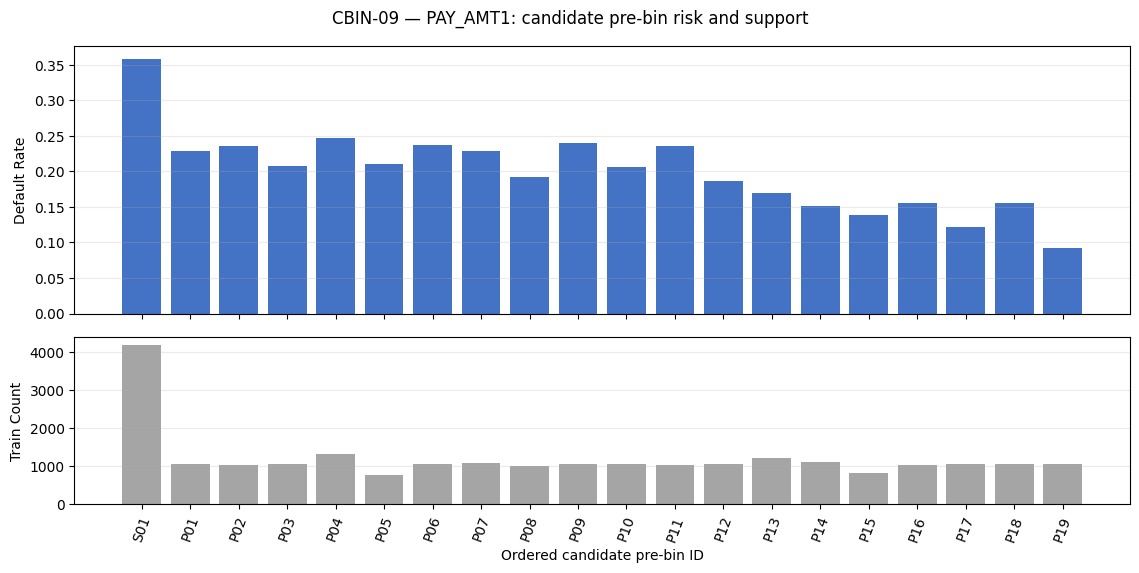

In [13]:
run_variable("PAY_AMT1","payment",19,"CBIN-09")


## CBIN-10 — PAY_AMT2 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 8.12% to 33.23%; smallest support 646 (2.692%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,4324,0.180167,2887,1437,0.332331,0.154459,0.270672,-0.560978,0.065193,None
1,P01,"[1, 419]",1.000000,419.000000,1037,0.043208,787,250,0.241080,0.042106,0.047090,-0.111871,0.000558,None
2,P02,"(419, 1000]",419.000000,1000.000000,1277,0.053208,973,304,0.238058,0.052057,0.057261,-0.095282,0.000496,None
3,P03,"(1000, 1200]",1000.000000,1200.000000,812,0.033833,634,178,0.219212,0.033920,0.033528,0.011627,0.000005,None
4,P04,"(1200, 1401]",1200.000000,1401.000000,1019,0.042458,756,263,0.258096,0.040447,0.049539,-0.202751,0.001843,None
5,P05,"(1401, 1597]",1401.000000,1597.000000,1034,0.043083,790,244,0.235977,0.042266,0.045960,-0.083774,0.000309,None
6,P06,"(1597, 1850]",1597.000000,1850.000000,1036,0.043167,784,252,0.243243,0.041945,0.047467,-0.123659,0.000683,None
7,P07,"(1850, 2000]",1850.000000,2000.000000,1330,0.055417,1030,300,0.225564,0.055107,0.056508,-0.025107,0.000035,None
8,P08,"(2000, 2200]",2000.000000,2200.000000,744,0.031000,602,142,0.190860,0.032208,0.026747,0.185792,0.001015,None
9,P09,"(2200, 2627]",2200.000000,2627.000000,1033,0.043042,814,219,0.212004,0.043550,0.041251,0.054250,0.000125,None


Raw pre-bin total IV: 0.161169810800 — diagnostic only; no variable-selection decision


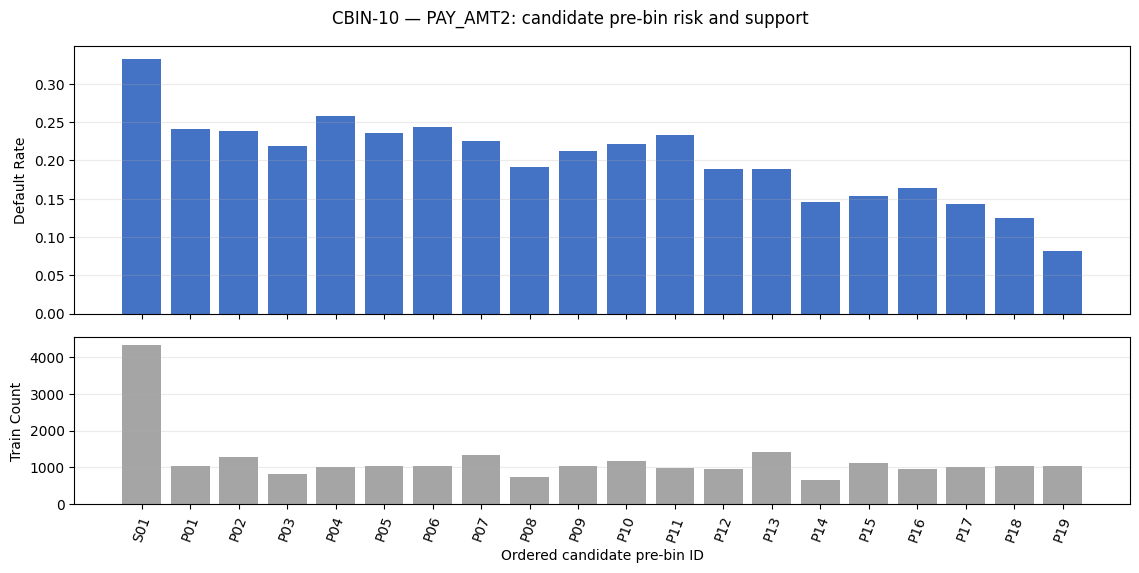

In [14]:
run_variable("PAY_AMT2","payment",19,"CBIN-10")


## CBIN-11 — PAY_AMT3 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 10.11% to 32.30%; smallest support 187 (0.779%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,4780,0.199167,3236,1544,0.323013,0.173131,0.290827,-0.518677,0.061046,None
1,P01,"[1, 360]",1.000000,360.000000,1016,0.042333,795,221,0.217520,0.042534,0.041627,0.021541,0.000020,None
2,P02,"(360, 642]",360.000000,642.000000,1010,0.042083,761,249,0.246535,0.040715,0.046901,-0.141458,0.000875,None
3,P03,"(642, 1000]",642.000000,1000.000000,1841,0.076708,1400,441,0.239544,0.074902,0.083066,-0.103456,0.000845,None
4,P04,"(1000, 1027]",1000.000000,1027.000000,187,0.007792,160,27,0.144385,0.008560,0.005086,0.520698,0.001809,None
5,P05,"(1027, 1287]",1027.000000,1287.000000,1008,0.042000,788,220,0.218254,0.042159,0.041439,0.017232,0.000012,None
6,P06,"(1287, 1500]",1287.000000,1500.000000,1173,0.048875,883,290,0.247229,0.047242,0.054624,-0.145194,0.001072,None
7,P07,"(1500, 1774]",1500.000000,1774.000000,847,0.035292,660,187,0.220779,0.035311,0.035223,0.002493,0.000000,None
8,P08,"(1774, 2000]",1774.000000,2000.000000,1457,0.060708,1120,337,0.231297,0.059922,0.063477,-0.057638,0.000205,None
9,P09,"(2000, 2201]",2000.000000,2201.000000,569,0.023708,465,104,0.182777,0.024878,0.019589,0.239008,0.001264,None


Raw pre-bin total IV: 0.141487929984 — diagnostic only; no variable-selection decision


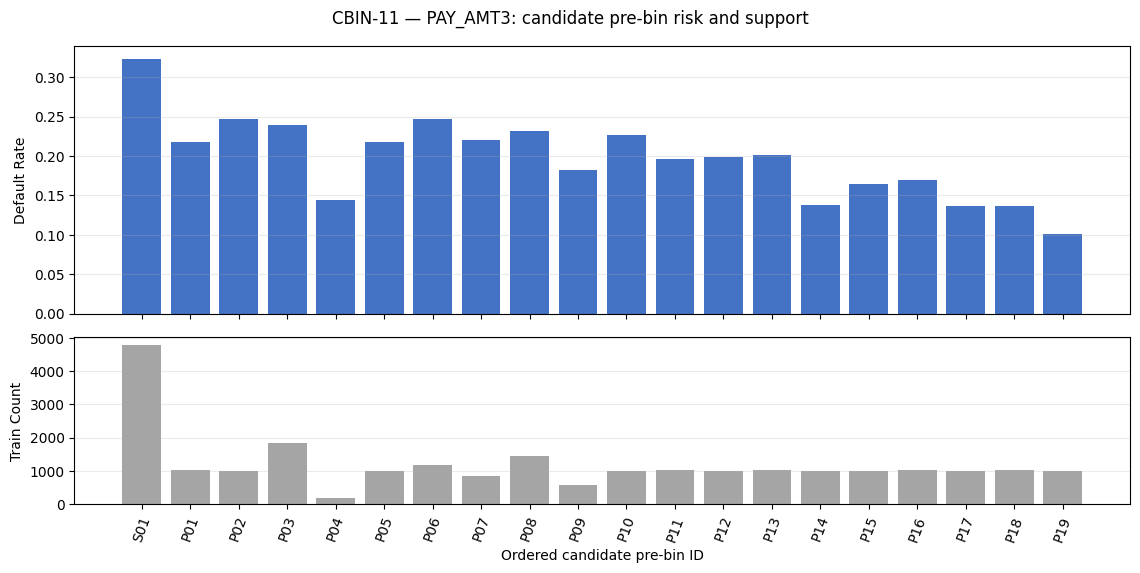

In [15]:
run_variable("PAY_AMT3","payment",19,"CBIN-11")


## CBIN-12 — PAY_AMT4 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 11.81% to 30.69%; smallest support 584 (2.433%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,5141,0.214208,3563,1578,0.306944,0.190627,0.297231,-0.444194,0.047353,None
1,P01,"[1, 315]",1.000000,315.000000,994,0.041417,799,195,0.196177,0.042748,0.036730,0.151723,0.000913,None
2,P02,"(315, 500]",315.000000,500.000000,1100,0.045833,857,243,0.220909,0.045851,0.045771,0.001738,0.000000,None
3,P03,"(500, 702]",500.000000,702.000000,889,0.037042,672,217,0.244094,0.035953,0.040874,-0.128278,0.000631,None
4,P04,"(702, 996]",702.000000,996.000000,989,0.041208,763,226,0.228514,0.040822,0.042569,-0.041916,0.000073,None
5,P05,"(996, 1000]",996.000000,1000.000000,1132,0.047167,841,291,0.257067,0.044995,0.054813,-0.197370,0.001938,None
6,P06,"(1000, 1200]",1000.000000,1200.000000,862,0.035917,669,193,0.223898,0.035793,0.036353,-0.015545,0.000009,None
7,P07,"(1200, 1500]",1200.000000,1500.000000,986,0.041083,729,257,0.260649,0.039003,0.048408,-0.216041,0.002032,None
8,P08,"(1500, 1965]",1500.000000,1965.000000,990,0.041250,766,224,0.226263,0.040982,0.042193,-0.029103,0.000035,None
9,P09,"(1965, 2000]",1965.000000,2000.000000,1004,0.041833,786,218,0.217131,0.042052,0.041062,0.023823,0.000024,None


Raw pre-bin total IV: 0.111417117658 — diagnostic only; no variable-selection decision


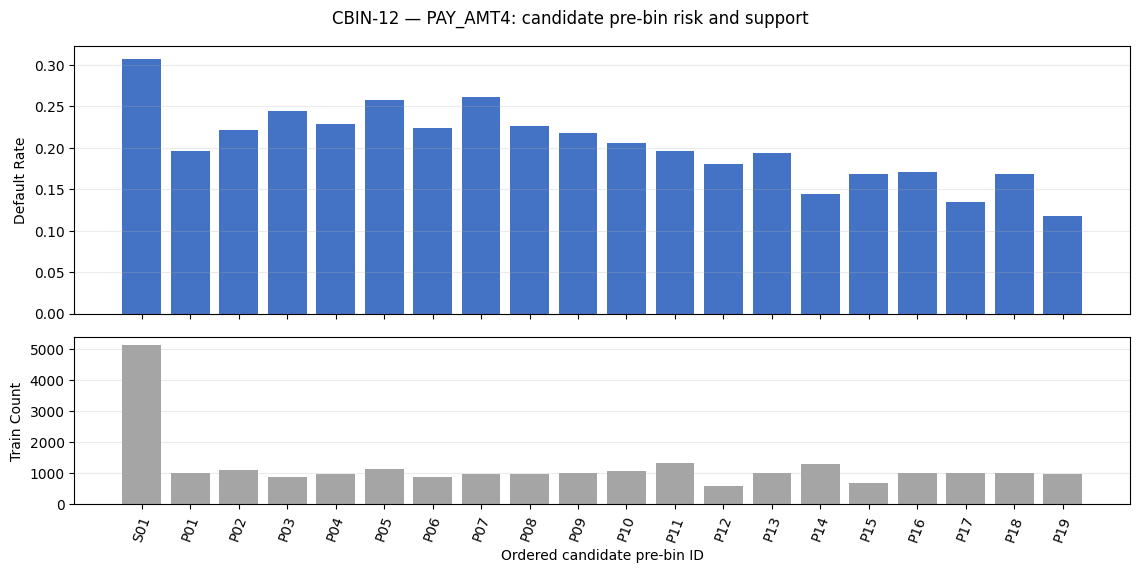

In [16]:
run_variable("PAY_AMT4","payment",19,"CBIN-12")


## CBIN-13 — PAY_AMT5 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 11.02% to 29.24%; smallest support 132 (0.550%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,5387,0.224458,3812,1575,0.292371,0.203948,0.296666,-0.374740,0.034745,None
1,P01,"[1, 337]",1.000000,337.000000,983,0.040958,780,203,0.206511,0.041731,0.038237,0.087449,0.000306,None
2,P02,"(337, 527]",337.000000,527.000000,978,0.040750,735,243,0.248466,0.039324,0.045771,-0.151830,0.000979,None
3,P03,"(527, 772]",527.000000,772.000000,979,0.040792,740,239,0.244127,0.039591,0.045018,-0.128452,0.000697,None
4,P04,"(772, 1000]",772.000000,1000.000000,1828,0.076167,1382,446,0.243982,0.073939,0.084008,-0.127671,0.001286,None
5,P05,"(1000, 1025]",1000.000000,1025.000000,132,0.005500,107,25,0.189394,0.005725,0.004709,0.195314,0.000198,None
6,P06,"(1025, 1300]",1025.000000,1300.000000,980,0.040833,758,222,0.226531,0.040554,0.041816,-0.030633,0.000039,None
7,P07,"(1300, 1600]",1300.000000,1600.000000,985,0.041042,747,238,0.241624,0.039966,0.044830,-0.114844,0.000559,None
8,P08,"(1600, 2000]",1600.000000,2000.000000,1785,0.074375,1374,411,0.230252,0.073511,0.077416,-0.051750,0.000202,None
9,P09,"(2000, 2055]",2000.000000,2055.000000,170,0.007083,144,26,0.152941,0.007704,0.004897,0.453078,0.001272,None


Raw pre-bin total IV: 0.095541078089 — diagnostic only; no variable-selection decision


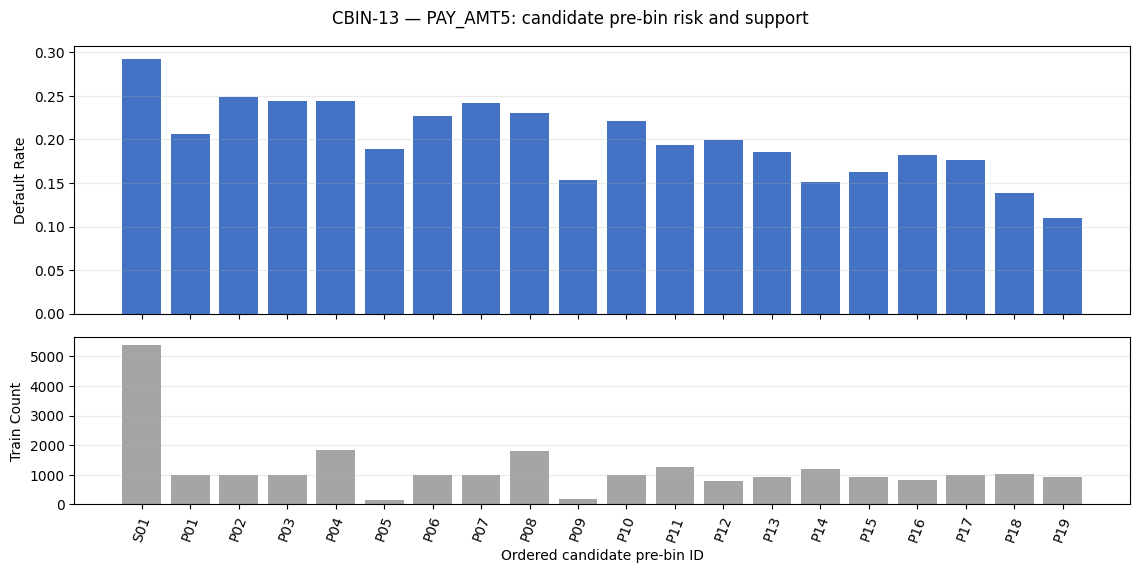

In [17]:
run_variable("PAY_AMT5","payment",19,"CBIN-13")


## CBIN-14 — PAY_AMT6 pre-bin diagnostics

Zero stays separately visible as a candidate state; positive values alone receive predictor-only quantiles. Zero is not frozen as a final bin. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 12.21% to 28.94%; smallest support 134 (0.558%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,5787,0.241125,4112,1675,0.289442,0.219999,0.315502,-0.360542,0.034433,None
1,P01,"[1, 341]",1.000000,341.000000,961,0.040042,740,221,0.229969,0.039591,0.041627,-0.050151,0.000102,None
2,P02,"(341, 530]",341.000000,530.000000,961,0.040042,728,233,0.242456,0.038949,0.043888,-0.119376,0.000590,None
3,P03,"(530, 780]",530.000000,780.000000,1016,0.042333,751,265,0.260827,0.040180,0.049915,-0.216963,0.002112,None
4,P04,"(780, 1000]",780.000000,1000.000000,1726,0.071917,1321,405,0.234647,0.070676,0.076286,-0.076381,0.000428,None
5,P05,"(1000, 1030]",1000.000000,1030.000000,134,0.005583,110,24,0.179104,0.005885,0.004521,0.263788,0.000360,None
6,P06,"(1030, 1328]",1030.000000,1328.000000,955,0.039792,738,217,0.227225,0.039484,0.040874,-0.034592,0.000048,None
7,P07,"(1328, 1632]",1328.000000,1632.000000,959,0.039958,708,251,0.261731,0.037879,0.047278,-0.221647,0.002083,None
8,P08,"(1632, 2000]",1632.000000,2000.000000,1708,0.071167,1326,382,0.223653,0.070943,0.071953,-0.014137,0.000014,None
9,P09,"(2000, 2100]",2000.000000,2100.000000,250,0.010417,200,50,0.200000,0.010700,0.009418,0.127656,0.000164,None


Raw pre-bin total IV: 0.102200190935 — diagnostic only; no variable-selection decision


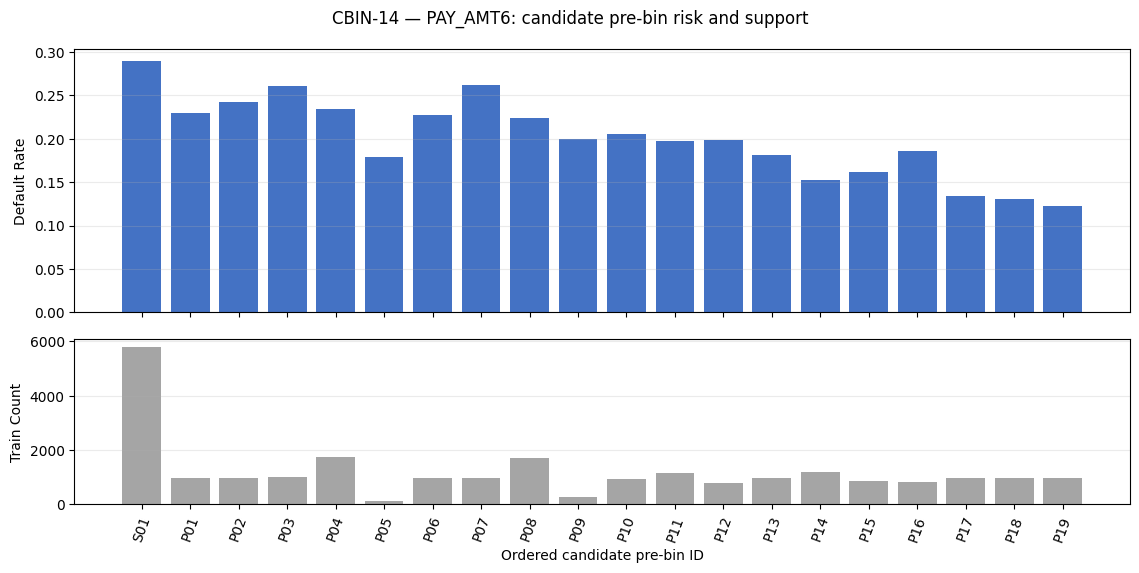

In [18]:
run_variable("PAY_AMT6","payment",19,"CBIN-14")


## CBIN-15 — current_utilization pre-bin diagnostics

Zero and >1 remain candidate anchors; only 0<utilization≤1 receives predictor-only quantiles. Values >1 are retained and mean nonnegative bill amount exceeds credit limit for this measure; they are not labeled errors. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 14.04% to 30.86%; smallest support 1,123 (4.679%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,2080,0.086667,1564,516,0.248077,0.083677,0.097193,-0.149743,0.002024,None
1,I01,"[2.77777777778e-06, 0.00333]",0.000003,0.003330,1126,0.046917,908,218,0.193606,0.048580,0.041062,0.168111,0.001264,None
2,I02,"(0.00333, 0.00821935483871]",0.003330,0.008219,1124,0.046833,910,214,0.190391,0.048687,0.040309,0.188830,0.001582,None
3,I03,"(0.00821935483871, 0.0161388888889]",0.008219,0.016139,1124,0.046833,927,197,0.175267,0.049596,0.037107,0.290111,0.003623,None
4,I04,"(0.0161388888889, 0.0294791666667]",0.016139,0.029479,1124,0.046833,960,164,0.145907,0.051362,0.030891,0.508428,0.010408,None
5,I05,"(0.0294791666667, 0.0535625]",0.029479,0.053562,1124,0.046833,957,167,0.148577,0.051201,0.031456,0.487171,0.009619,None
6,I06,"(0.0535625, 0.0917592592593]",0.053562,0.091759,1124,0.046833,958,166,0.147687,0.051255,0.031268,0.494221,0.009878,None
7,I07,"(0.0917592592593, 0.1504]",0.091759,0.150400,1125,0.046875,967,158,0.140444,0.051736,0.029761,0.552965,0.012152,None
8,I08,"(0.1504, 0.237525714286]",0.150400,0.237526,1123,0.046792,919,204,0.181656,0.049168,0.038425,0.246527,0.002648,None
9,I09,"(0.237525714286, 0.3329625]",0.237526,0.332962,1124,0.046833,893,231,0.205516,0.047777,0.043511,0.093530,0.000399,None


Raw pre-bin total IV: 0.089327800406 — diagnostic only; no variable-selection decision


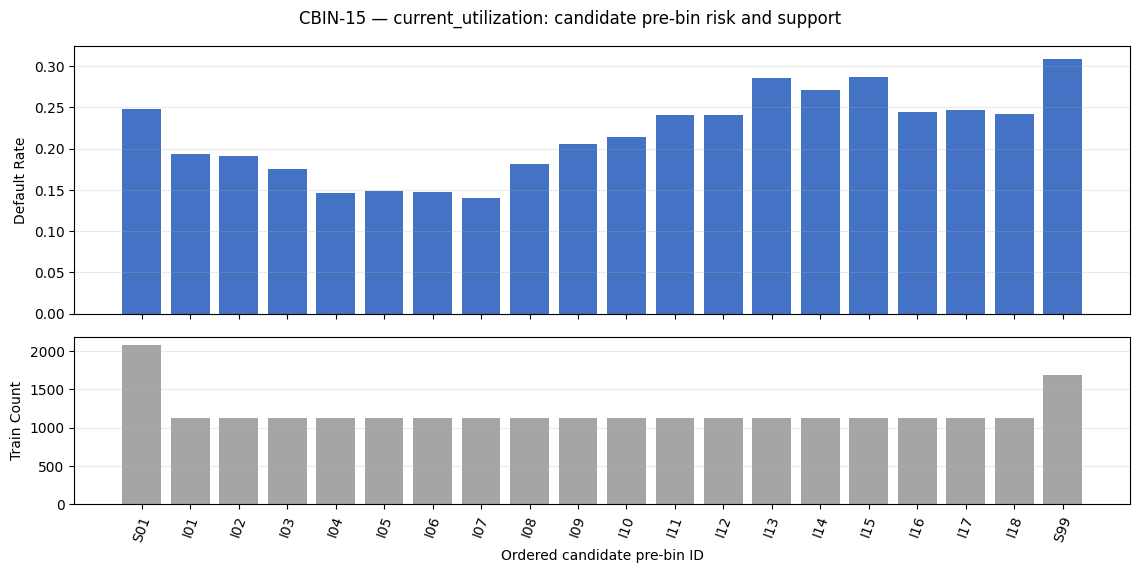

In [19]:
run_variable("current_utilization","utilization",18,"CBIN-15")


## CBIN-16 — avg_utilization pre-bin diagnostics

Zero and >1 remain candidate anchors; only 0<utilization≤1 receives predictor-only quantiles. Values >1 are retained and mean nonnegative bill amount exceeds credit limit for this measure; they are not labeled errors. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 13.63% to 35.80%; smallest support 508 (2.117%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,771,0.032125,495,276,0.357977,0.026483,0.051987,-0.674482,0.017202,None
1,I01,"[1.79487179487e-05, 0.0031]",0.000018,0.003100,1264,0.052667,1003,261,0.206487,0.053662,0.049162,0.087592,0.000394,None
2,I02,"(0.0031, 0.00800588235294]",0.003100,0.008006,1262,0.052583,999,263,0.208399,0.053448,0.049539,0.075962,0.000297,None
3,I03,"(0.00800588235294, 0.0160345238095]",0.008006,0.016035,1262,0.052583,1036,226,0.179081,0.055428,0.042569,0.263949,0.003394,None
4,I04,"(0.0160345238095, 0.0283422222222]",0.016035,0.028342,1262,0.052583,1064,198,0.156894,0.056926,0.037295,0.422885,0.008302,None
5,I05,"(0.0283422222222, 0.0492416666667]",0.028342,0.049242,1263,0.052625,1089,174,0.137767,0.058263,0.032775,0.575321,0.014664,None
6,I06,"(0.0492416666667, 0.0816666666667]",0.049242,0.081667,1262,0.052583,1090,172,0.136292,0.058317,0.032398,0.587800,0.015235,None
7,I07,"(0.0816666666667, 0.132706666667]",0.081667,0.132707,1262,0.052583,1080,182,0.144216,0.057782,0.034281,0.522071,0.012269,None
8,I08,"(0.132706666667, 0.205016666667]",0.132707,0.205017,1262,0.052583,1076,186,0.147385,0.057568,0.035035,0.496620,0.011190,None
9,I09,"(0.205016666667, 0.293037666667]",0.205017,0.293038,1262,0.052583,1034,228,0.180666,0.055321,0.042946,0.253206,0.003133,None


Raw pre-bin total IV: 0.148279318085 — diagnostic only; no variable-selection decision


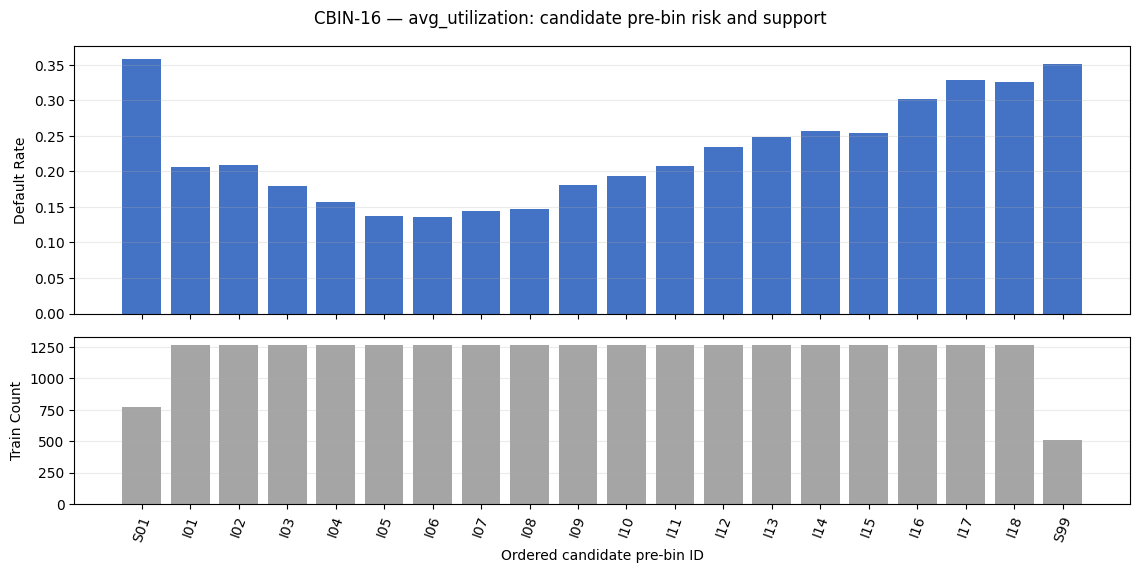

In [20]:
run_variable("avg_utilization","utilization",18,"CBIN-16")


## CBIN-17 — max_utilization pre-bin diagnostics

Zero and >1 remain candidate anchors; only 0<utilization≤1 receives predictor-only quantiles. Values >1 are retained and mean nonnegative bill amount exceeds credit limit for this measure; they are not labeled errors. Candidate intervals reflect Train observed values and are not production-complete final bins.


Question: What broad, persistent Train risk regions are visible across the ordered candidate pre-bins?
Why it matters: Human review needs target-independent detail before any supervised final grouping.
Observed factual pattern: 20 bins; Default Rate spans 12.98% to 35.80%; smallest support 771 (3.212%); duplicate-edge reduction 0.
Human decision needed: review broad neighboring patterns, support, and interpretability without freezing a cutpoint or issuing a merge instruction.


,Pre-bin ID,Numeric interval / candidate state,Lower bound,Upper bound,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,S01,Zero (=0),0.000000,0.000000,771,0.032125,495,276,0.357977,0.026483,0.051987,-0.674482,0.017202,None
1,I01,"[0.000107692307692, 0.00758571428571]",0.000108,0.007586,1118,0.046583,878,240,0.214669,0.046974,0.045206,0.038369,0.000068,None
2,I02,"(0.00758571428571, 0.0170642857143]",0.007586,0.017064,1117,0.046542,867,250,0.223814,0.046386,0.047090,-0.015061,0.000011,None
3,I03,"(0.0170642857143, 0.032225]",0.017064,0.032225,1116,0.046500,918,198,0.177419,0.049115,0.037295,0.275292,0.003254,None
4,I04,"(0.032225, 0.0524936170213]",0.032225,0.052494,1117,0.046542,945,172,0.153984,0.050559,0.032398,0.445052,0.008083,None
5,I05,"(0.0524936170213, 0.0810666666667]",0.052494,0.081067,1117,0.046542,951,166,0.148612,0.050880,0.031268,0.486888,0.009549,None
6,I06,"(0.0810666666667, 0.1203]",0.081067,0.120300,1116,0.046500,933,183,0.163978,0.049917,0.034470,0.370280,0.005720,None
7,I07,"(0.1203, 0.172909677419]",0.120300,0.172910,1117,0.046542,972,145,0.129812,0.052004,0.027312,0.643983,0.015901,None
8,I08,"(0.172909677419, 0.244175675676]",0.172910,0.244176,1116,0.046500,942,174,0.155914,0.050399,0.032775,0.430311,0.007584,None
9,I09,"(0.244175675676, 0.3352]",0.244176,0.335200,1117,0.046542,937,180,0.161146,0.050131,0.033905,0.391088,0.006346,None


Raw pre-bin total IV: 0.113684478483 — diagnostic only; no variable-selection decision


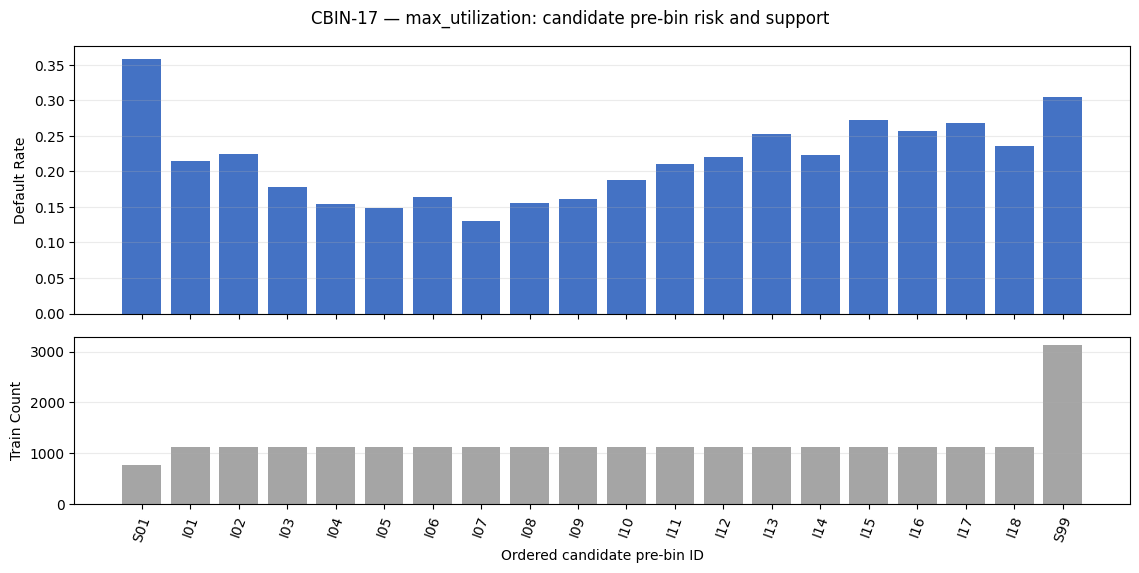

In [21]:
run_variable("max_utilization","utilization",18,"CBIN-17")


## 21. BILL_AMT cross-month factual comparison

This comparison asks whether broad risk regions recur across months or a break is isolated. It does not calculate a stability score, harmonize cutpoints, rank months, or propose final boundaries.


In [22]:
bill_rows=[]
for v in BILL_VARIABLES:
 t=prebin_tables[v]; neg=t.loc[t["Numeric interval / candidate state"]=="Negative (<0)"].iloc[0]; zero=t.loc[t["Numeric interval / candidate state"]=="Zero (=0)"].iloc[0]; pos=t.loc[t["Pre-bin ID"].str.startswith("P")]
 bill_rows.append({"Variable":v,"Actual bins":len(t),"Negative Count":int(neg.Count),"Negative % Train":neg["% Train"],"Negative Default Rate":neg["Default Rate"],"Negative WOE":neg.WOE,"Zero Count":int(zero.Count),"Zero % Train":zero["% Train"],"Zero Default Rate":zero["Default Rate"],"Zero WOE":zero.WOE,"First positive rate":pos.iloc[0]["Default Rate"],"Last positive rate":pos.iloc[-1]["Default Rate"]})
bill_cross_month=pd.DataFrame(bill_rows); display(bill_cross_month)
print("Factual comparison: negative and zero support/risk vary by month, while ordered positive-domain profiles show recurring broad regions plus local spikes/dips. Any one-month-only break requires noise review; no common cutpoint is inferred.")


,Variable,Actual bins,Negative Count,Negative % Train,Negative Default Rate,Negative WOE,Zero Count,Zero % Train,Zero Default Rate,Zero WOE,First positive rate,Last positive rate
0,BILL_AMT1,20,468,0.019500,0.175214,0.290479,1612,0.067167,0.269231,-0.260110,0.226754,0.198850
1,BILL_AMT2,20,522,0.021750,0.172414,0.309977,1986,0.082750,0.244209,-0.128901,0.222222,0.202181
2,BILL_AMT3,20,515,0.021458,0.186408,0.214884,2308,0.096167,0.237868,-0.094236,0.226160,0.200680
3,BILL_AMT4,20,530,0.022083,0.171698,0.315001,2555,0.106458,0.240313,-0.107675,0.244425,0.212748
4,BILL_AMT5,20,524,0.021833,0.196565,0.149265,2828,0.117833,0.243989,-0.127704,0.222802,0.216216
5,BILL_AMT6,20,556,0.023167,0.185252,0.222525,3223,0.134292,0.232392,-0.063786,0.219556,0.219947


Factual comparison: negative and zero support/risk vary by month, while ordered positive-domain profiles show recurring broad regions plus local spikes/dips. Any one-month-only break requires noise review; no common cutpoint is inferred.


## 22. PAY_AMT cross-month factual comparison

Zero-state and low/positive-domain evidence are compared descriptively only. No shared cutpoints, formal stability score, harmonization, or selection is produced.


In [23]:
assert (train_work[PAY_AMT_VARIABLES]>=0).all().all()
pay_rows=[]
for v in PAY_AMT_VARIABLES:
 t=prebin_tables[v]; zero=t.loc[t["Numeric interval / candidate state"]=="Zero (=0)"].iloc[0]; pos=t.loc[t["Pre-bin ID"].str.startswith("P")]
 pay_rows.append({"Variable":v,"Actual bins":len(t),"Zero Count":int(zero.Count),"Zero % Train":zero["% Train"],"Zero Default Rate":zero["Default Rate"],"Zero WOE":zero.WOE,"First positive rate":pos.iloc[0]["Default Rate"],"Second positive rate":pos.iloc[min(1,len(pos)-1)]["Default Rate"],"Last positive rate":pos.iloc[-1]["Default Rate"]})
pay_cross_month=pd.DataFrame(pay_rows); display(pay_cross_month)
print("Factual comparison: zero states consistently have substantial support; positive-domain risk generally differs across ordered regions, with month-specific local spikes/dips treated as possible noise rather than final boundaries.")


,Variable,Actual bins,Zero Count,Zero % Train,Zero Default Rate,Zero WOE,First positive rate,Second positive rate,Last positive rate
0,PAY_AMT1,20,4180,0.174167,0.358134,-0.675166,0.228271,0.235351,0.092131
1,PAY_AMT2,20,4324,0.180167,0.332331,-0.560978,0.241080,0.238058,0.081159
2,PAY_AMT3,20,4780,0.199167,0.323013,-0.518677,0.217520,0.246535,0.101090
3,PAY_AMT4,20,5141,0.214208,0.306944,-0.444194,0.196177,0.220909,0.118135
4,PAY_AMT5,20,5387,0.224458,0.292371,-0.374740,0.206511,0.248466,0.110151
5,PAY_AMT6,20,5787,0.241125,0.289442,-0.360542,0.229969,0.242456,0.122129


Factual comparison: zero states consistently have substantial support; positive-domain risk generally differs across ordered regions, with month-specific local spikes/dips treated as possible noise rather than final boundaries.


## 23. Utilization anchor evidence

Zero and >1 are candidate business anchors, not final bins. The table compares them with neighboring interior candidates without inspecting Holdout or deciding final treatment.


In [24]:
util_rows=[]
for v in UTILIZATION_VARIABLES:
 t=prebin_tables[v]; zero=t.loc[t["Numeric interval / candidate state"]=="Zero (=0)"].iloc[0]; above=t.loc[t["Numeric interval / candidate state"]==">1"].iloc[0]; interior=t.loc[t["Pre-bin ID"].str.startswith("I")]
 util_rows.append({"Variable":v,"Zero Count":int(zero.Count),"Zero Default Rate":zero["Default Rate"],"Zero WOE":zero.WOE,"First interior rate":interior.iloc[0]["Default Rate"],"Last interior rate":interior.iloc[-1]["Default Rate"],">1 Count":int(above.Count),">1 % Train":above["% Train"],">1 Default Rate":above["Default Rate"],">1 WOE":above.WOE})
util_anchor_evidence=pd.DataFrame(util_rows); display(util_anchor_evidence)
print("Human decision needed: assess whether zero and >1 differ persistently from neighboring interior regions; no anchor is frozen here.")


,Variable,Zero Count,Zero Default Rate,Zero WOE,First interior rate,Last interior rate,>1 Count,>1 % Train,>1 Default Rate,>1 WOE
0,current_utilization,2080,0.248077,-0.149743,0.193606,0.241993,1685,0.070208,0.308605,-0.451991
1,avg_utilization,771,0.357977,-0.674482,0.206487,0.325674,508,0.021167,0.350394,-0.641330
2,max_utilization,771,0.357977,-0.674482,0.214669,0.235663,3129,0.130375,0.304251,-0.431501


Human decision needed: assess whether zero and >1 differ persistently from neighboring interior regions; no anchor is frozen here.


## 24. Fixed-order 17-variable factual summary

Raw pre-bin IV is diagnostic only — no variable-selection decision. The order is fixed by scope and is not a ranking.


In [25]:
summary_rows=[]
for v in CONTINUOUS_VARIABLES:
 m=prebin_metadata[v]; t=prebin_tables[v]; smallest=t.loc[t.Count.idxmin()]
 summary_rows.append({"Variable":v,"Requested total bins":m["requested_total_bins"],"Actual candidate bins":m["actual_candidate_bins"],"Unique values":m["unique_value_count"],"Duplicate-boundary reduction":m["duplicate_boundary_reduction"],"Special states":m["special_states"],"Smallest bin count":int(smallest.Count),"Smallest bin % Train":smallest["% Train"],"Raw pre-bin total IV":prebin_iv_totals[v],"Zero-event flag":"Yes" if (t["Zero-event flag"]!="None").any() else "No","Factual note":f"Default Rate range {t['Default Rate'].min():.2%}–{t['Default Rate'].max():.2%}; Human review only."})
prebin_summary=pd.DataFrame(summary_rows); assert prebin_summary.Variable.tolist()==CONTINUOUS_VARIABLES; display(prebin_summary)
print("diagnostic only — no variable-selection decision")


,Variable,Requested total bins,Actual candidate bins,Unique values,Duplicate-boundary reduction,Special states,Smallest bin count,Smallest bin % Train,Raw pre-bin total IV,Zero-event flag,Factual note
0,AGE,20,20,55,0,none,649,0.027042,0.023245,No,Default Rate range 18.79%–28.30%; Human review...
1,LIMIT_BAL,20,18,80,2,none,600,0.025000,0.201675,No,Default Rate range 10.09%–36.85%; Human review...
2,BILL_AMT1,20,20,18671,0,<0; =0,468,0.019500,0.024475,No,Default Rate range 17.52%–27.09%; Human review...
3,BILL_AMT2,20,20,18400,0,<0; =0,522,0.021750,0.022333,No,Default Rate range 17.24%–26.80%; Human review...
4,BILL_AMT3,20,20,18112,0,<0; =0,515,0.021458,0.017565,No,Default Rate range 17.77%–26.49%; Human review...
5,BILL_AMT4,20,20,17764,0,<0; =0,530,0.022083,0.023340,No,Default Rate range 17.17%–28.49%; Human review...
6,BILL_AMT5,20,20,17304,0,<0; =0,524,0.021833,0.028634,No,Default Rate range 15.34%–26.68%; Human review...
7,BILL_AMT6,20,20,16970,0,<0; =0,556,0.023167,0.029269,No,Default Rate range 15.30%–27.43%; Human review...
8,PAY_AMT1,20,20,6924,0,=0,768,0.032000,0.189100,No,Default Rate range 9.21%–35.81%; Human review ...
9,PAY_AMT2,20,20,6882,0,=0,646,0.026917,0.161170,No,Default Rate range 8.12%–33.23%; Human review ...


diagnostic only — no variable-selection decision


## 25. Candidate observations and mandatory Human Checkpoint

Allowed observations are limited to broad neighboring risk regions, recurring multi-month patterns, and isolated low-support spikes that may be noise. No final cutpoint, explicit merge instruction, optimal-bin claim, or variable recommendation is made.

**Overfitting guardrail:** Do not merge two adjacent pre-bins merely because their current Train default rates happen to be close.

Future Stage 4.3B domain-completeness rule: approved final outer intervals must eventually extend to `(-∞, c1]` and `(ck, +∞)` rather than stop at Train min/max. Test min/max was not inspected, and no outer cutpoint is finalized here.

Human review groups: AGE/LIMIT_BAL; six BILL variables; six PAY_AMT variables; three utilization variables.


In [26]:
assert list(prebin_tables)==CONTINUOUS_VARIABLES and len(prebin_tables)==17 and len(prebin_metadata)==17 and len(prebin_iv_totals)==17
assert figure_ids==[f"CBIN-{i:02d}" for i in range(1,18)] and len(set(figure_ids))==17
assert all(len(prebin_tables[v])==prebin_metadata[v]["actual_candidate_bins"] for v in CONTINUOUS_VARIABLES)
assert all(int(prebin_tables[v].Count.sum())==24000 for v in CONTINUOUS_VARIABLES)
assert all(prebin_assignments[v].notna().all() for v in CONTINUOUS_VARIABLES)
assert TEST_SEAL_STATUS.startswith("SEALED") and train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[BILL_VARIABLES],raw_bills_before,check_exact=True)
JITTER_USED=False; TARGET_DRIVEN_BOUNDARIES=False; AUTOMATIC_MERGE=False; FINAL_CUTPOINTS=False; NICE_NUMBER_ADJUSTMENT=False; STAGE_43B_STARTED=False; VARIABLE_SELECTION=False; MODELING=False; KFOLD=False; AUC_KS=False; TEST_PREDICTOR_OR_RISK_ANALYSIS=False
assert not any([JITTER_USED,TARGET_DRIVEN_BOUNDARIES,AUTOMATIC_MERGE,FINAL_CUTPOINTS,NICE_NUMBER_ADJUSTMENT,STAGE_43B_STARTED,VARIABLE_SELECTION,MODELING,KFOLD,AUC_KS,TEST_PREDICTOR_OR_RISK_ANALYSIS])
display(pd.DataFrame({"Result":["PASS — exactly 17 fixed-order tables","PASS — CBIN-01 through CBIN-17 unique","PASS — predictor-only deterministic boundaries and assignments","PASS — duplicate boundaries explicitly collapsed; no jitter/noise","PASS — Holdout deleted after technical identity assertions","PASS — no merge/final cutpoint/nice-number adjustment","PASS — no selection/model/KFold/AUC/KS/Stage 4.3B","PENDING — Architect/user Human Checkpoint"]},index=["Tables","Figures","Determinism","Ties","Holdout","Binning boundary","Scope exclusions","Next gate"]))
print("Stage 4.3A complete — final continuous binning pending Architect/user Human Checkpoint.")


,Result
Tables,PASS — exactly 17 fixed-order tables
Figures,PASS — CBIN-01 through CBIN-17 unique
Determinism,PASS — predictor-only deterministic boundaries...
Ties,PASS — duplicate boundaries explicitly collaps...
Holdout,PASS — Holdout deleted after technical identit...
Binning boundary,PASS — no merge/final cutpoint/nice-number adj...
Scope exclusions,PASS — no selection/model/KFold/AUC/KS/Stage 4.3B
Next gate,PENDING — Architect/user Human Checkpoint


Stage 4.3A complete — final continuous binning pending Architect/user Human Checkpoint.


# Stage 4.3B — Human-Approved Final Continuous Binning

This section implements the frozen four-group Human Checkpoint decisions exactly. It does not search, optimize, merge, split, rank, select, model, or inspect Holdout predictor/target behavior. Stage 4.3A history and CBIN-01–CBIN-17 remain above.


In [27]:
FINAL_AGE_ORDER=["<=25","26–35","36–49","50+"]
FINAL_LIMIT_ORDER=["<=30k","(30k,140k]","(140k,240k]",">240k"]
FINAL_BILL_ORDER=["Negative","Zero","(0,10k]","(10k,40k]",">40k"]
FINAL_PAY_ORDER=["0","(0,5k]","(5k,20k]",">20k"]
FINAL_UTIL_ORDER=["0","(0,0.2]","(0.2,0.6]","(0.6,1]",">1"]
FINAL_ORDERS={"AGE":FINAL_AGE_ORDER,"LIMIT_BAL":FINAL_LIMIT_ORDER,**{v:FINAL_BILL_ORDER for v in BILL_VARIABLES},**{v:FINAL_PAY_ORDER for v in PAY_AMT_VARIABLES},**{v:FINAL_UTIL_ORDER for v in UTILIZATION_VARIABLES}}
FINAL_DEFINITIONS={
"AGE":[("B01","<=25","(-∞,25]"),("B02","26–35","(25,35]"),("B03","36–49","(35,49]"),("B04","50+","(49,+∞)")],
"LIMIT_BAL":[("B01","<=30k","(-∞,30000]"),("B02","(30k,140k]","(30000,140000]"),("B03","(140k,240k]","(140000,240000]"),("B04",">240k","(240000,+∞)")],
**{v:[("B01","Negative","(-∞,0)"),("B02","Zero","{0}"),("B03","(0,10k]","(0,10000]"),("B04","(10k,40k]","(10000,40000]"),("B05",">40k","(40000,+∞)")] for v in BILL_VARIABLES},
**{v:[("B01","0","{0}"),("B02","(0,5k]","(0,5000]"),("B03","(5k,20k]","(5000,20000]"),("B04",">20k","(20000,+∞)")] for v in PAY_AMT_VARIABLES},
**{v:[("B01","0","{0}"),("B02","(0,0.2]","(0,0.20]"),("B03","(0.2,0.6]","(0.20,0.60]"),("B04","(0.6,1]","(0.60,1]"),("B05",">1","(1,+∞)")] for v in UTILIZATION_VARIABLES}}
assert list(FINAL_ORDERS)==CONTINUOUS_VARIABLES and set(FINAL_DEFINITIONS)==set(CONTINUOUS_VARIABLES)
assert all([x[1] for x in FINAL_DEFINITIONS[v]]==FINAL_ORDERS[v] for v in CONTINUOUS_VARIABLES)
final_mapping_summary=pd.DataFrame({"Variables":["AGE","LIMIT_BAL","BILL_AMT1–6","PAY_AMT1–6","current_utilization","avg_utilization","max_utilization"],"Final bins":["<=25 / 26–35 / 36–49 / 50+","<=30k / (30k,140k] / (140k,240k] / >240k","<0 / =0 / (0,10k] / (10k,40k] / >40k","=0 / (0,5k] / (5k,20k] / >20k","=0 / (0,0.2] / (0.2,0.6] / (0.6,1] / >1","same","same"]}); display(final_mapping_summary)
print("FROZEN — implementation only; no cutpoint search or redesign.")


,Variables,Final bins
0,AGE,<=25 / 26–35 / 36–49 / 50+
1,LIMIT_BAL,"<=30k / (30k,140k] / (140k,240k] / >240k"
2,BILL_AMT1–6,"<0 / =0 / (0,10k] / (10k,40k] / >40k"
3,PAY_AMT1–6,"=0 / (0,5k] / (5k,20k] / >20k"
4,current_utilization,"=0 / (0,0.2] / (0.2,0.6] / (0.6,1] / >1"
5,avg_utilization,same
6,max_utilization,same


FROZEN — implementation only; no cutpoint search or redesign.


## 26. Human Checkpoint decisions and explicit deterministic mapping helpers

AGE uses four coarse intervals; labels are presentation aids only. LIMIT_BAL freezes 30k/140k/240k without 150k/250k robustness search. All BILL months share Negative/Zero/10k/40k thresholds. All PAY_AMT months share 0/5k/20k. All utilization measures share exact 0/0.2/0.6/1 comparisons with no pre-assignment rounding.


In [28]:
def _finite_number(value,variable):
    if pd.isna(value): raise ValueError(f"{variable}: missing input is invalid")
    if not isinstance(value,(int,float,np.integer,np.floating)): raise ValueError(f"{variable}: nonnumeric input is invalid")
    value=float(value)
    if not np.isfinite(value): raise ValueError(f"{variable}: non-finite input is invalid")
    return value
def map_age(value):
    x=_finite_number(value,"AGE")
    if x<=25:return "<=25"
    if x<=35:return "26–35"
    if x<=49:return "36–49"
    return "50+"
def map_limit(value):
    x=_finite_number(value,"LIMIT_BAL")
    if x<=30000:return "<=30k"
    if x<=140000:return "(30k,140k]"
    if x<=240000:return "(140k,240k]"
    return ">240k"
def map_bill(value):
    x=_finite_number(value,"BILL_AMT")
    if x<0:return "Negative"
    if x==0:return "Zero"
    if x<=10000:return "(0,10k]"
    if x<=40000:return "(10k,40k]"
    return ">40k"
def map_payment(value):
    x=_finite_number(value,"PAY_AMT")
    if x<0: raise ValueError("PAY_AMT: negative input is outside valid domain [0,+∞)")
    if x==0:return "0"
    if x<=5000:return "(0,5k]"
    if x<=20000:return "(5k,20k]"
    return ">20k"
def map_utilization(value):
    x=_finite_number(value,"utilization")
    if x<0: raise ValueError("utilization: negative input is outside valid domain [0,+∞)")
    if x==0:return "0"
    if x<=.20:return "(0,0.2]"
    if x<=.60:return "(0.2,0.6]"
    if x<=1:return "(0.6,1]"
    return ">1"
FINAL_MAPPERS={"AGE":map_age,"LIMIT_BAL":map_limit,**{v:map_bill for v in BILL_VARIABLES},**{v:map_payment for v in PAY_AMT_VARIABLES},**{v:map_utilization for v in UTILIZATION_VARIABLES}}
assert list(FINAL_MAPPERS)==CONTINUOUS_VARIABLES
print("Helpers ready — source value only, explicit validation, target/Test independent.")


Helpers ready — source value only, explicit validation, target/Test independent.


## 27. Synthetic boundary and domain-completeness tests

These assertions use synthetic values only. They deliberately include values outside Train observed ranges and exact floating-point successors at utilization boundaries. No Test lookup is used.


In [29]:
assert [map_age(x) for x in (-100,25,26,35,36,49,50,200)]==["<=25","<=25","26–35","26–35","36–49","36–49","50+","50+"]
assert [map_limit(x) for x in (0,30000,30001,140000,140001,240000,240001,1e9)]==["<=30k","<=30k","(30k,140k]","(30k,140k]","(140k,240k]","(140k,240k]",">240k",">240k"]
assert [map_bill(x) for x in (-1,0,np.nextafter(0,1),10000,10001,40000,40001,1e12)]==["Negative","Zero","(0,10k]","(0,10k]","(10k,40k]","(10k,40k]",">40k",">40k"]
assert [map_payment(x) for x in (0,.01,5000,5001,20000,20001,1e12)]==["0","(0,5k]","(0,5k]","(5k,20k]","(5k,20k]",">20k",">20k"]
assert [map_utilization(x) for x in (0,np.nextafter(0,1),.2,np.nextafter(.2,np.inf),.6,np.nextafter(.6,np.inf),1,np.nextafter(1,np.inf),10)]==["0","(0,0.2]","(0,0.2]","(0.2,0.6]","(0.2,0.6]","(0.6,1]","(0.6,1]",">1",">1"]
def assert_rejected(function,value):
    try:function(value)
    except ValueError:return True
    return False
assert assert_rejected(map_payment,-1) and assert_rejected(map_utilization,-1)
for function in (map_age,map_limit,map_bill,map_payment,map_utilization):
    for invalid in (None,np.nan,np.inf,-np.inf): assert assert_rejected(function,invalid)
print("PASS — AGE/LIMIT/BILL/PAY/utilization synthetic boundaries and outer-domain coverage.")
print("PASS — negative PAY/utilization and all missing/non-finite inputs explicitly rejected.")
print("No Test object or Test value used.")


PASS — AGE/LIMIT/BILL/PAY/utilization synthetic boundaries and outer-domain coverage.
PASS — negative PAY/utilization and all missing/non-finite inputs explicitly rejected.
No Test object or Test value used.


## 28. Apply exactly 17 frozen mappings to Train

Only explicit `_BIN` columns are added in memory. ID, target, row order, and all 17 source variables are retained exactly.


In [30]:
phase_b_ids_before=train_work[ID_COL].copy(deep=True); phase_b_target_before=train_work[TARGET].copy(deep=True); phase_b_sources_before=train_work[CONTINUOUS_VARIABLES].copy(deep=True); phase_b_index_before=train_work.index.copy()
FINAL_BIN_COLUMNS=[]
for variable in CONTINUOUS_VARIABLES:
    column=f"{variable}_BIN"; labels=train_work[variable].map(FINAL_MAPPERS[variable]); train_work[column]=pd.Categorical(labels,categories=FINAL_ORDERS[variable],ordered=True); FINAL_BIN_COLUMNS.append(column)
    assert train_work[column].notna().all() and train_work[variable].map(FINAL_MAPPERS[variable]).tolist()==labels.tolist()
assert len(FINAL_BIN_COLUMNS)==17 and len(set(FINAL_BIN_COLUMNS))==17
assert len(train_work)==24000 and train_work.index.equals(phase_b_index_before) and train_work[ID_COL].equals(phase_b_ids_before) and train_work[TARGET].equals(phase_b_target_before)
pd.testing.assert_frame_equal(train_work[CONTINUOUS_VARIABLES],phase_b_sources_before,check_exact=True)
assert (train_work[PAY_AMT_VARIABLES]>=0).all().all() and (train_work[UTILIZATION_VARIABLES]>=0).all().all()
assert all(FINAL_MAPPERS[v] is map_bill for v in BILL_VARIABLES) and all(FINAL_MAPPERS[v] is map_payment for v in PAY_AMT_VARIABLES) and all(FINAL_MAPPERS[v] is map_utilization for v in UTILIZATION_VARIABLES)
display(pd.DataFrame({"Result":["PASS — exactly 17 final bin columns","PASS — 24,000 rows; ID/order/target unchanged","PASS — all 17 source columns unchanged","PASS — no missing/unmapped labels","PASS — rerun labels deterministic","PASS — family helpers identical"]},index=["Columns","Row integrity","Source integrity","Coverage","Determinism","Family rules"]))


,Result
Columns,PASS — exactly 17 final bin columns
Row integrity,"PASS — 24,000 rows; ID/order/target unchanged"
Source integrity,PASS — all 17 source columns unchanged
Coverage,PASS — no missing/unmapped labels
Determinism,PASS — rerun labels deterministic
Family rules,PASS — family helpers identical


## 29. Final grouped WOE / IV helper

Frozen convention remains Good=0, Bad=1, WOE=`ln(Dist Good / Dist Bad)`. No smoothing is applied or authorized.


In [31]:
FINAL_TABLE_COLUMNS=["Final Bin ID","Display Label","Formal Numeric Definition","Count","% Train","Good","Bad","Default Rate","Dist Good","Dist Bad","WOE","IV Contribution"]
final_tables={}; final_iv_totals={}; final_risk_shapes={}
def build_final_table(variable):
    defs=pd.DataFrame(FINAL_DEFINITIONS[variable],columns=["Final Bin ID","Display Label","Formal Numeric Definition"])
    col=f"{variable}_BIN"; g=train_work.groupby(col,observed=True)[TARGET].agg(Count="size",Bad="sum").loc[FINAL_ORDERS[variable]]; g["Good"]=g.Count-g.Bad
    table=defs.merge(g.reset_index().rename(columns={col:"Display Label"}),on="Display Label",validate="one_to_one")
    table["% Train"]=table.Count/24000; table["Default Rate"]=table.Bad/table.Count; table["Dist Good"]=table.Good/TOTAL_GOOD; table["Dist Bad"]=table.Bad/TOTAL_BAD
    table["WOE"]=np.log(table["Dist Good"]/table["Dist Bad"]); table["IV Contribution"]=(table["Dist Good"]-table["Dist Bad"])*table.WOE; table=table[FINAL_TABLE_COLUMNS]
    assert (table.Count==table.Good+table.Bad).all() and int(table.Count.sum())==24000 and int(table.Good.sum())==18691 and int(table.Bad.sum())==5309
    assert np.isclose(table["% Train"].sum(),1) and np.isclose(table["Dist Good"].sum(),1) and np.isclose(table["Dist Bad"].sum(),1)
    assert (table.Good>0).all() and (table.Bad>0).all() and np.isfinite(table[["WOE","IV Contribution"]]).all().all()
    total=float(table["IV Contribution"].sum()); assert np.isfinite(total); return table,total

def render_final(variable,table,figure_id):
    x=np.arange(len(table)); labels=table["Display Label"].tolist(); fig,axes=plt.subplots(2,1,figsize=(9.2,5.4),sharex=True,gridspec_kw={"height_ratios":[2,1.25]})
    axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].grid(axis="y",alpha=.25)
    for i,v in enumerate(table["Default Rate"]):axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
    axes[1].bar(x,table.Count,color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Frozen final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels,rotation=15)
    for i,v in enumerate(table.Count):axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
    fig.suptitle(f"{figure_id} — {variable}: final grouped risk and support"); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append(figure_id)
def run_final(variable,figure_id):
    table,total=build_final_table(variable); final_tables[variable]=table; final_iv_totals[variable]=total
    rates=table["Default Rate"].tolist(); shape=("mild/non-monotonic pattern retained" if variable=="AGE" else "non-monotonicity permitted and retained" if variable in BILL_VARIABLES else "ordered broad behavior recorded without forced monotonicity")
    final_risk_shapes[variable]=shape
    display(table); print(f"{variable} — Final grouped total IV: {total:.12f}"); print("Observed final pattern:",shape); print("Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion."); render_final(variable,table,figure_id)
SMOOTHING_USED=False
print("Final helper ready — exact Train aggregation, no smoothing, no selection.")


Final helper ready — exact Train aggregation, no smoothing, no selection.


## CBIN-18 — AGE Final Binning

- **Final grouping:** `<=25 / 26–35 / 36–49 / 50+`
- **Human-approved rationale:** Four coarse bins preserve weak U-shaped nonlinearity without fitting small fluctuations.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,<=25,"(-∞,25]",3104,0.129333,2268,836,0.269330,0.121342,0.157468,-0.260614,0.009415
1,B02,26–35,"(25,35]",10446,0.435250,8371,2075,0.198641,0.447863,0.390846,0.136174,0.007764
2,B03,36–49,"(35,49]",8319,0.346625,6464,1855,0.222984,0.345835,0.349407,-0.010275,0.000037
3,B04,50+,"(49,+∞)",2131,0.088792,1588,543,0.254810,0.084961,0.102279,-0.185517,0.003213


AGE — Final grouped total IV: 0.020428857210
Observed final pattern: mild/non-monotonic pattern retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


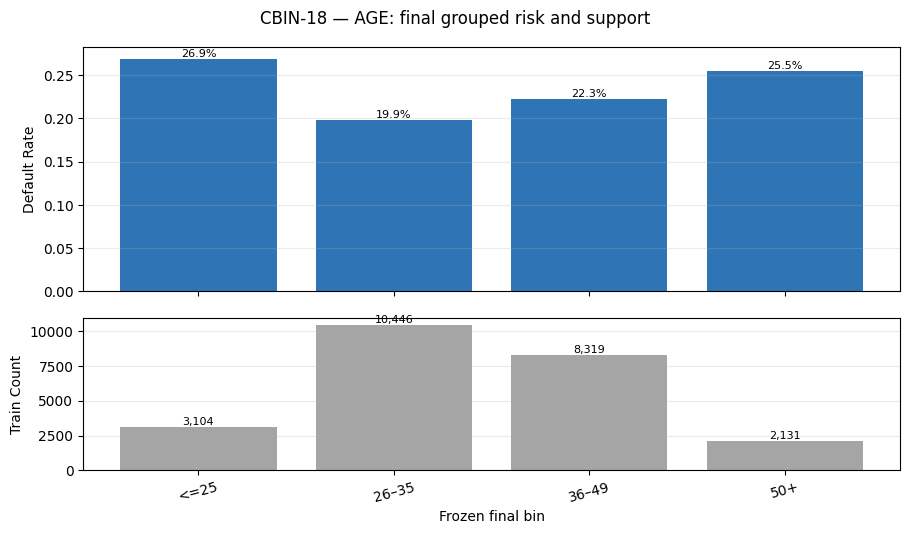

In [32]:
run_final("AGE","CBIN-18")


## CBIN-19 — LIMIT_BAL Final Binning

- **Final grouping:** `<=30k / (30k,140k] / (140k,240k] / >240k`
- **Human-approved rationale:** Frozen 30k/140k/240k broad risk regions; no robustness search.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,<=30k,"(-∞,30000]",3256,0.135667,2067,1189,0.365172,0.110588,0.223959,-0.705653,0.080001
1,B02,"(30k,140k]","(30000,140000]",8957,0.373208,6660,2297,0.256447,0.356321,0.432662,-0.194123,0.014819
2,B03,"(140k,240k]","(140000,240000]",6178,0.257417,5095,1083,0.175299,0.272591,0.203993,0.289886,0.019886
3,B04,>240k,"(240000,+∞)",5609,0.233708,4869,740,0.131931,0.260500,0.139386,0.625355,0.075739


LIMIT_BAL — Final grouped total IV: 0.190444892886
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


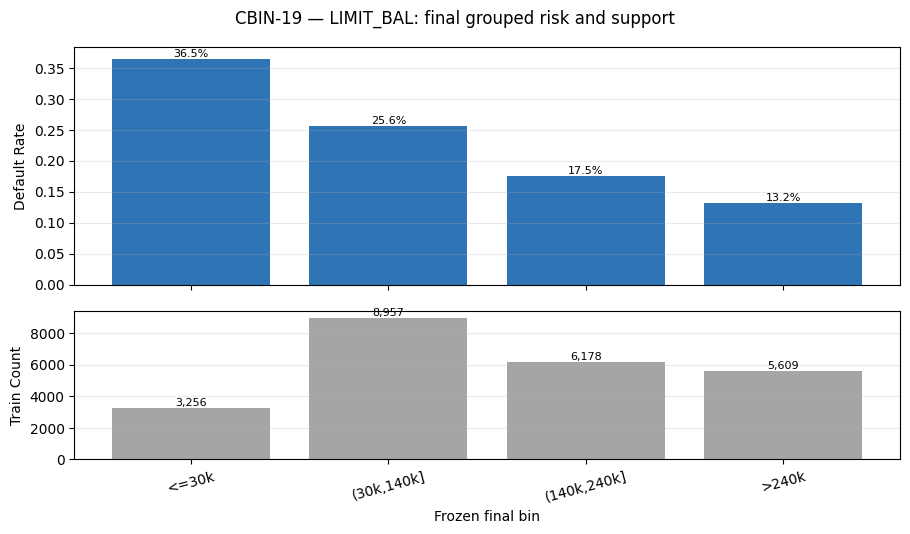

In [33]:
run_final("LIMIT_BAL","CBIN-19")


## CBIN-20 — BILL_AMT1 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",468,0.019500,386,82,0.175214,0.020652,0.015445,0.290479,0.001512
1,B02,Zero,{0},1612,0.067167,1178,434,0.269231,0.063025,0.081748,-0.260110,0.004870
2,B03,"(0,10k]","(0,10000]",6599,0.274958,5202,1397,0.211699,0.278316,0.263138,0.056077,0.000851
3,B04,"(10k,40k]","(10000,40000]",6061,0.252542,4574,1487,0.245339,0.244717,0.280090,-0.135011,0.004776
4,B05,>40k,"(40000,+∞)",9260,0.385833,7351,1909,0.206156,0.393291,0.359578,0.089618,0.003021


BILL_AMT1 — Final grouped total IV: 0.015030576031
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


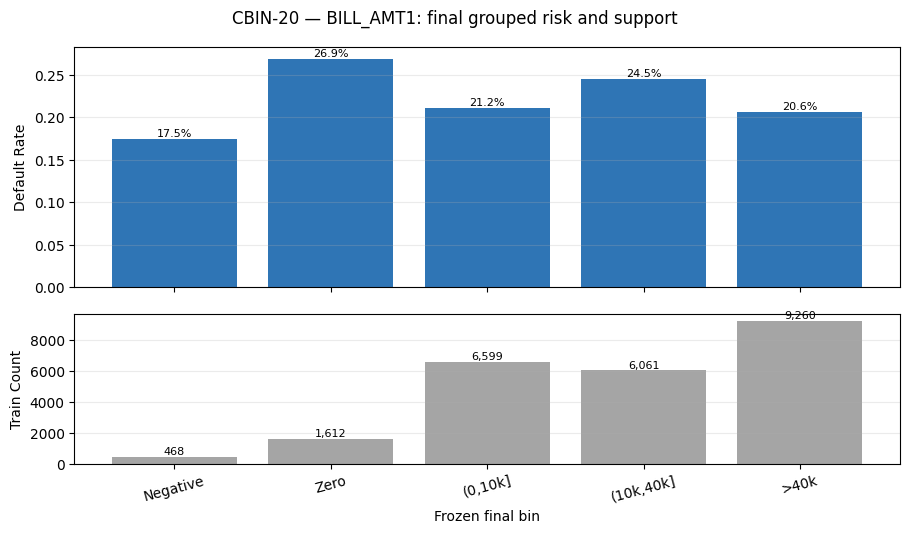

In [34]:
run_final("BILL_AMT1","CBIN-20")


## CBIN-21 — BILL_AMT2 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",522,0.021750,432,90,0.172414,0.023113,0.016952,0.309977,0.001910
1,B02,Zero,{0},1986,0.082750,1501,485,0.244209,0.080306,0.091354,-0.128901,0.001424
2,B03,"(0,10k]","(0,10000]",6339,0.264125,5020,1319,0.208077,0.268578,0.248446,0.077917,0.001569
3,B04,"(10k,40k]","(10000,40000]",6180,0.257500,4638,1542,0.249515,0.248141,0.290450,-0.157436,0.006661
4,B05,>40k,"(40000,+∞)",8973,0.373875,7100,1873,0.208737,0.379862,0.352797,0.073915,0.002000


BILL_AMT2 — Final grouped total IV: 0.013563868019
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


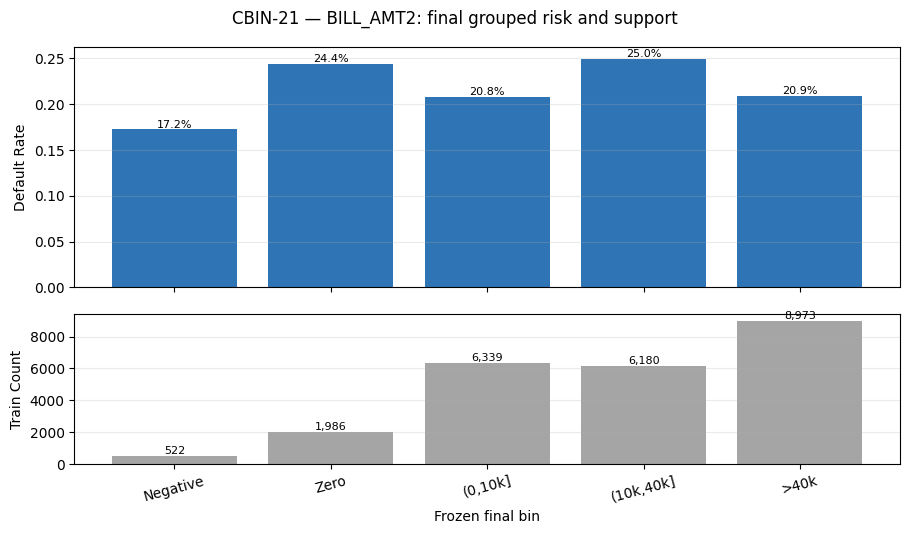

In [35]:
run_final("BILL_AMT2","CBIN-21")


## CBIN-22 — BILL_AMT3 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",515,0.021458,419,96,0.186408,0.022417,0.018083,0.214884,0.000931
1,B02,Zero,{0},2308,0.096167,1759,549,0.237868,0.094109,0.103409,-0.094236,0.000876
2,B03,"(0,10k]","(0,10000]",6160,0.256667,4881,1279,0.207630,0.261142,0.240912,0.080633,0.001631
3,B04,"(10k,40k]","(10000,40000]",6483,0.270125,4877,1606,0.247725,0.260928,0.302505,-0.147855,0.006147
4,B05,>40k,"(40000,+∞)",8534,0.355583,6755,1779,0.208460,0.361404,0.335091,0.075593,0.001989


BILL_AMT3 — Final grouped total IV: 0.011575527611
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


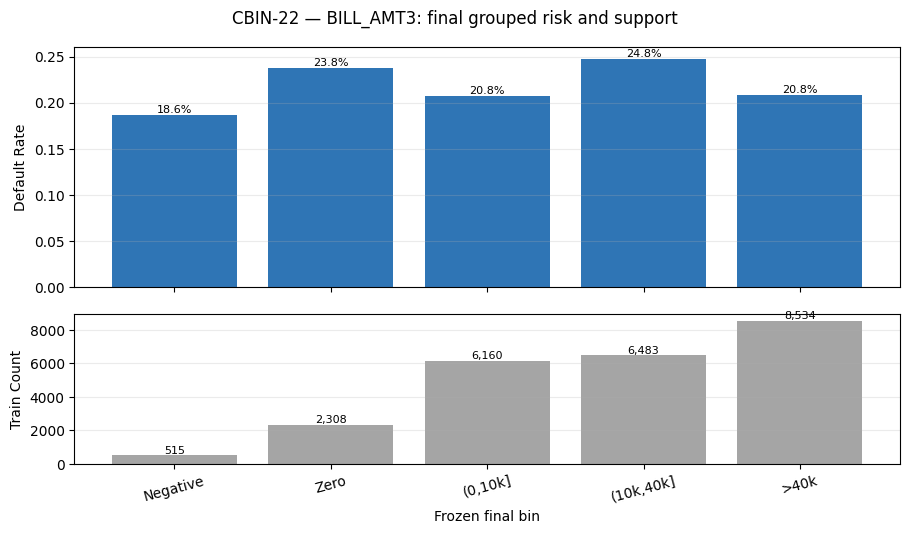

In [36]:
run_final("BILL_AMT3","CBIN-22")


## CBIN-23 — BILL_AMT4 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",530,0.022083,439,91,0.171698,0.023487,0.017141,0.315001,0.001999
1,B02,Zero,{0},2555,0.106458,1941,614,0.240313,0.103847,0.115653,-0.107675,0.001271
2,B03,"(0,10k]","(0,10000]",6141,0.255875,4875,1266,0.206155,0.260821,0.238463,0.089619,0.002004
3,B04,"(10k,40k]","(10000,40000]",6976,0.290667,5260,1716,0.245986,0.281419,0.323225,-0.138504,0.005790
4,B05,>40k,"(40000,+∞)",7798,0.324917,6176,1622,0.208002,0.330426,0.305519,0.078372,0.001952


BILL_AMT4 — Final grouped total IV: 0.013016361921
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


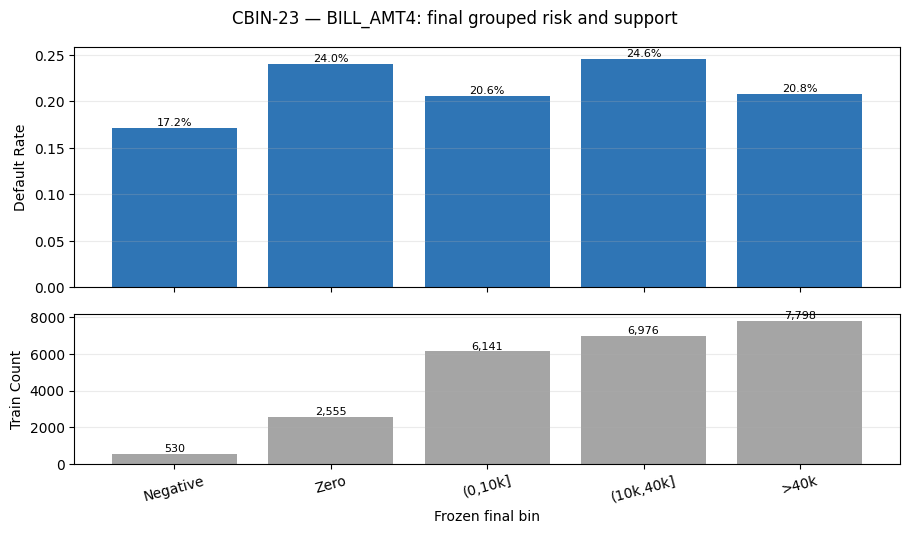

In [37]:
run_final("BILL_AMT4","CBIN-23")


## CBIN-24 — BILL_AMT5 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",524,0.021833,421,103,0.196565,0.022524,0.019401,0.149265,0.000466
1,B02,Zero,{0},2828,0.117833,2138,690,0.243989,0.114387,0.129968,-0.127704,0.001990
2,B03,"(0,10k]","(0,10000]",6336,0.264000,5083,1253,0.197759,0.271949,0.236014,0.141722,0.005093
3,B04,"(10k,40k]","(10000,40000]",7023,0.292625,5274,1749,0.249039,0.282168,0.329441,-0.154894,0.007322
4,B05,>40k,"(40000,+∞)",7289,0.303708,5775,1514,0.207710,0.308972,0.285176,0.080144,0.001907


BILL_AMT5 — Final grouped total IV: 0.016778116821
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


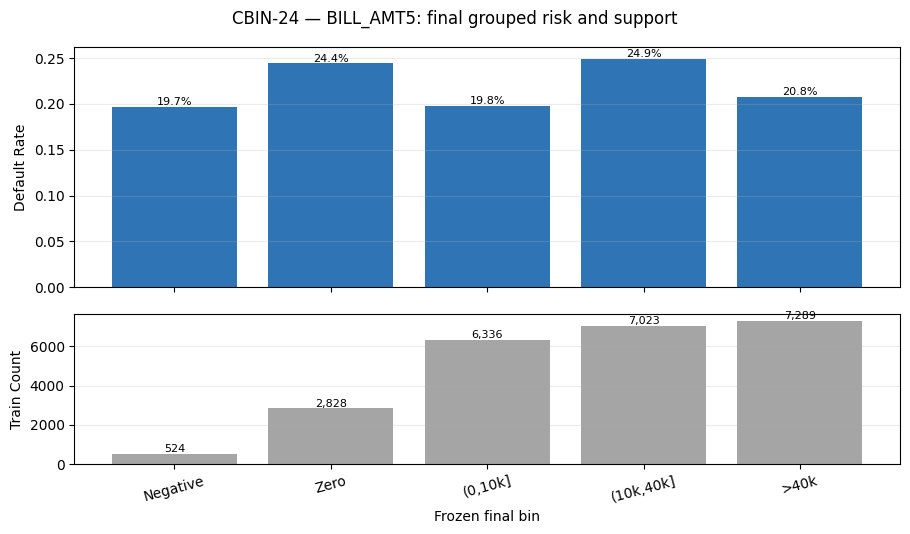

In [38]:
run_final("BILL_AMT5","CBIN-24")


## CBIN-25 — BILL_AMT6 Final Binning

- **Final grouping:** `Negative / Zero / (0,10k] / (10k,40k] / >40k`
- **Human-approved rationale:** Common cross-month 10k/40k rule preserves broad structure without false precision.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,Negative,"(-∞,0)",556,0.023167,453,103,0.185252,0.024236,0.019401,0.222525,0.001076
1,B02,Zero,{0},3223,0.134292,2474,749,0.232392,0.132363,0.141081,-0.063786,0.000556
2,B03,"(0,10k]","(0,10000]",6369,0.265375,5105,1264,0.198461,0.273126,0.238086,0.137301,0.004811
3,B04,"(10k,40k]","(10000,40000]",6764,0.281833,5065,1699,0.251183,0.270986,0.320023,-0.166324,0.008156
4,B05,>40k,"(40000,+∞)",7088,0.295333,5594,1494,0.210779,0.299288,0.281409,0.061599,0.001101


BILL_AMT6 — Final grouped total IV: 0.015700367798
Observed final pattern: non-monotonicity permitted and retained
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


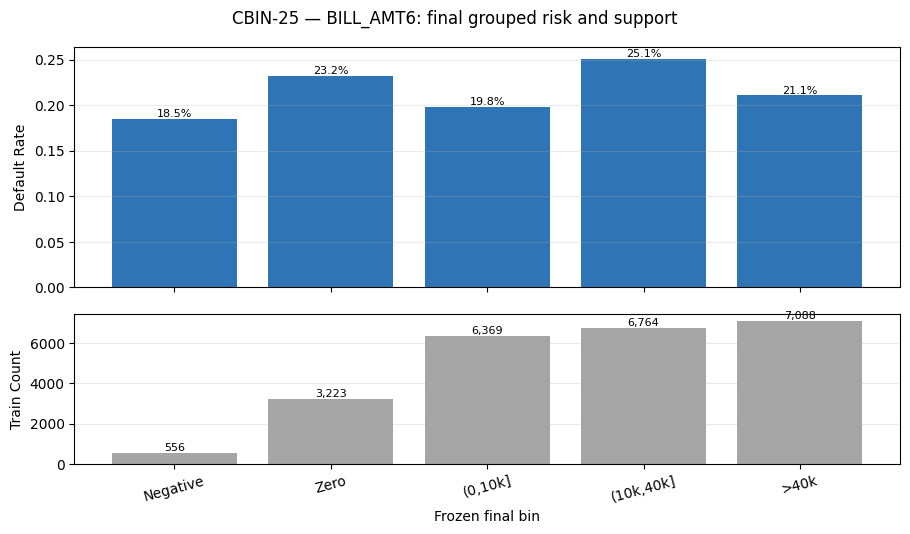

In [39]:
run_final("BILL_AMT6","CBIN-25")


## CBIN-26 — PAY_AMT1 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},4180,0.174167,2683,1497,0.358134,0.143545,0.281974,-0.675166,0.093463
1,B02,"(0,5k]","(0,5000]",13723,0.571792,10739,2984,0.217445,0.574555,0.562064,0.021979,0.000275
2,B03,"(5k,20k]","(5000,20000]",5055,0.210625,4323,732,0.144807,0.231288,0.137879,0.517286,0.048319
3,B04,>20k,"(20000,+∞)",1042,0.043417,946,96,0.092131,0.050613,0.018083,1.029256,0.033482


PAY_AMT1 — Final grouped total IV: 0.175537864049
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


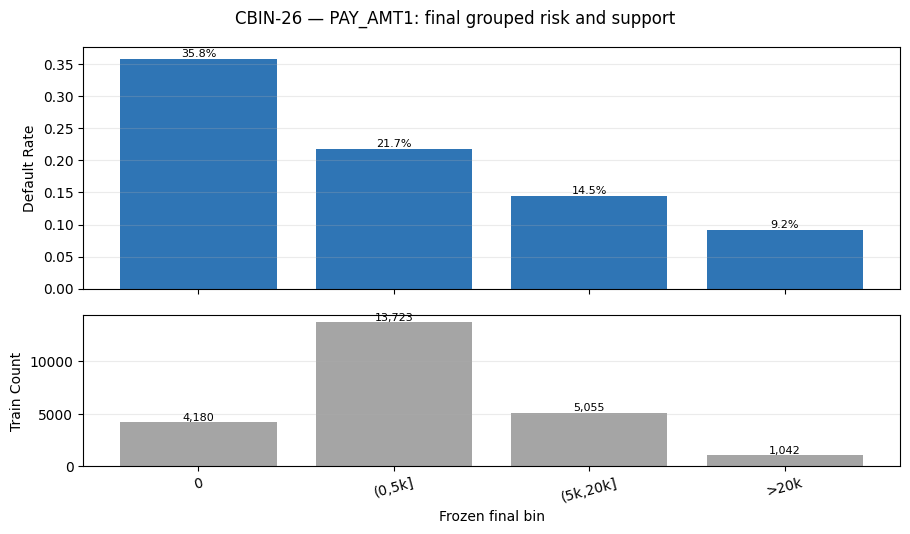

In [40]:
run_final("PAY_AMT1","CBIN-26")


## CBIN-27 — PAY_AMT2 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},4324,0.180167,2887,1437,0.332331,0.154459,0.270672,-0.560978,0.065193
1,B02,"(0,5k]","(0,5000]",13854,0.577250,10766,3088,0.222896,0.575999,0.581654,-0.009769,0.000055
2,B03,"(5k,20k]","(5000,20000]",4740,0.197500,4043,697,0.147046,0.216307,0.131286,0.499318,0.042452
3,B04,>20k,"(20000,+∞)",1082,0.045083,995,87,0.080407,0.053234,0.016387,1.178196,0.043413


PAY_AMT2 — Final grouped total IV: 0.151113586876
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


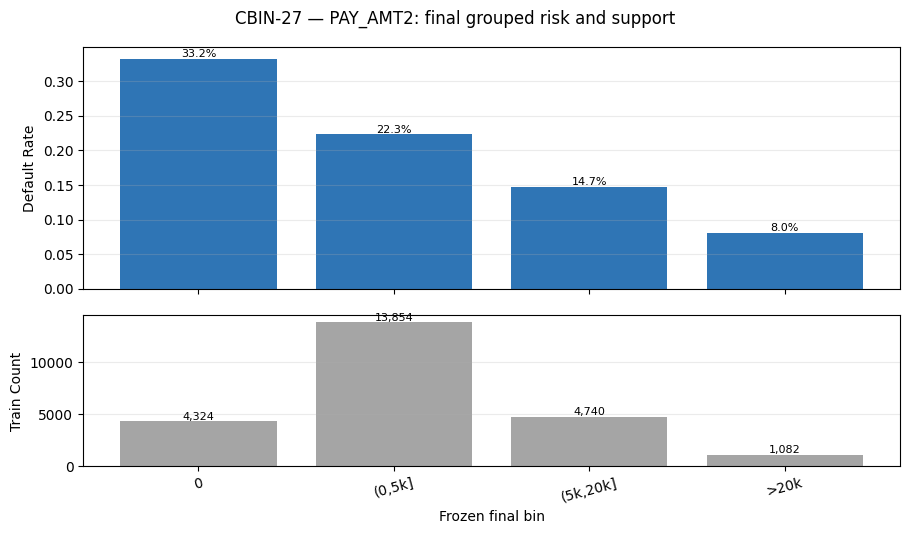

In [41]:
run_final("PAY_AMT2","CBIN-27")


## CBIN-28 — PAY_AMT3 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},4780,0.199167,3236,1544,0.323013,0.173131,0.290827,-0.518677,0.061046
1,B02,"(0,5k]","(0,5000]",14043,0.585125,11009,3034,0.216051,0.589000,0.571482,0.030193,0.000529
2,B03,"(5k,20k]","(5000,20000]",4168,0.173667,3539,629,0.150912,0.189342,0.118478,0.468830,0.033223
3,B04,>20k,"(20000,+∞)",1009,0.042042,907,102,0.101090,0.048526,0.019213,0.926531,0.027160


PAY_AMT3 — Final grouped total IV: 0.121957912222
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


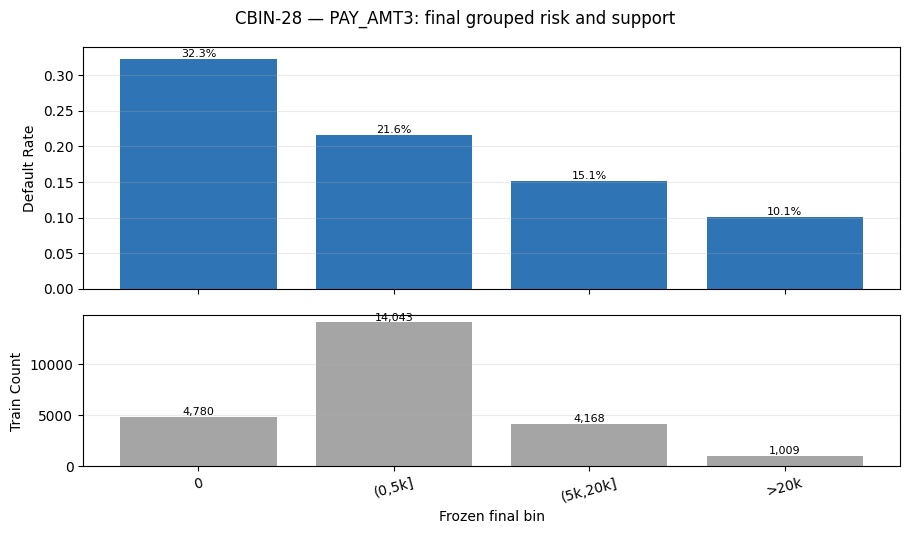

In [42]:
run_final("PAY_AMT3","CBIN-28")


## CBIN-29 — PAY_AMT4 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},5141,0.214208,3563,1578,0.306944,0.190627,0.297231,-0.444194,0.047353
1,B02,"(0,5k]","(0,5000]",14201,0.591708,11176,3025,0.213013,0.597935,0.569787,0.048219,0.001357
2,B03,"(5k,20k]","(5000,20000]",3693,0.153875,3101,592,0.160303,0.165909,0.111509,0.397335,0.021615
3,B04,>20k,"(20000,+∞)",965,0.040208,851,114,0.118135,0.045530,0.021473,0.751575,0.018081


PAY_AMT4 — Final grouped total IV: 0.088405981704
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


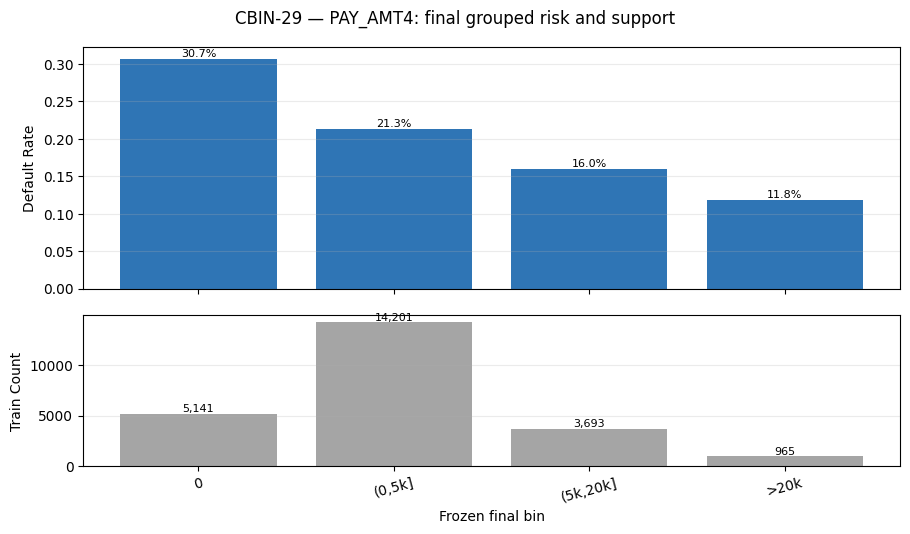

In [43]:
run_final("PAY_AMT4","CBIN-29")


## CBIN-30 — PAY_AMT5 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},5387,0.224458,3812,1575,0.292371,0.203948,0.296666,-0.374740,0.034745
1,B02,"(0,5k]","(0,5000]",13941,0.580875,10923,3018,0.216484,0.584399,0.568469,0.027638,0.000440
2,B03,"(5k,20k]","(5000,20000]",3746,0.156083,3132,614,0.163908,0.167567,0.115653,0.370793,0.019250
3,B04,>20k,"(20000,+∞)",926,0.038583,824,102,0.110151,0.044085,0.019213,0.830559,0.020658


PAY_AMT5 — Final grouped total IV: 0.075093140327
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


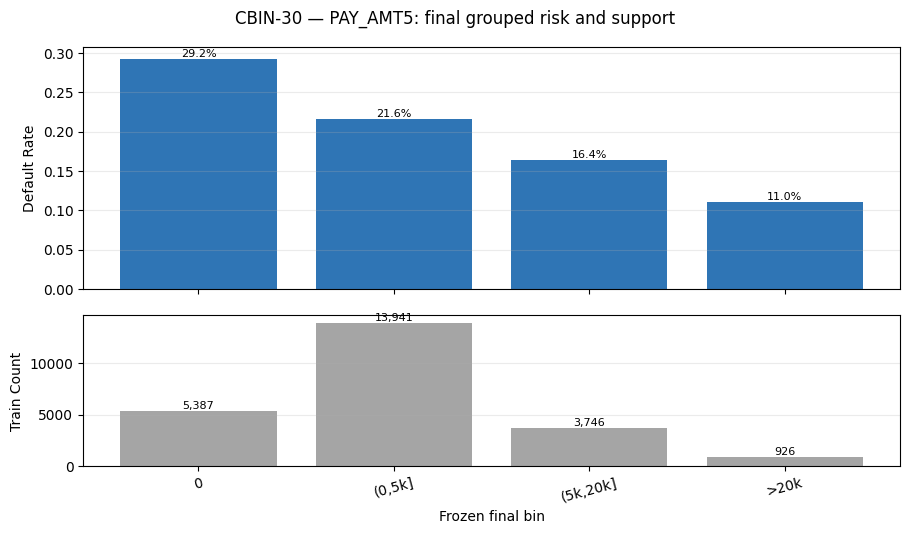

In [44]:
run_final("PAY_AMT5","CBIN-30")


## CBIN-31 — PAY_AMT6 Final Binning

- **Final grouping:** `0 / (0,5k] / (5k,20k] / >20k`
- **Human-approved rationale:** Common 5k/20k rule retains major payment separation without fragmentation.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},5787,0.241125,4112,1675,0.289442,0.219999,0.315502,-0.360542,0.034433
1,B02,"(0,5k]","(0,5000]",13662,0.569250,10689,2973,0.217611,0.571880,0.559992,0.021005,0.000250
2,B03,"(5k,20k]","(5000,20000]",3513,0.146375,2976,537,0.152861,0.159221,0.101149,0.453699,0.026347
3,B04,>20k,"(20000,+∞)",1038,0.043250,914,124,0.119461,0.048901,0.023357,0.738910,0.018875


PAY_AMT6 — Final grouped total IV: 0.079904481549
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


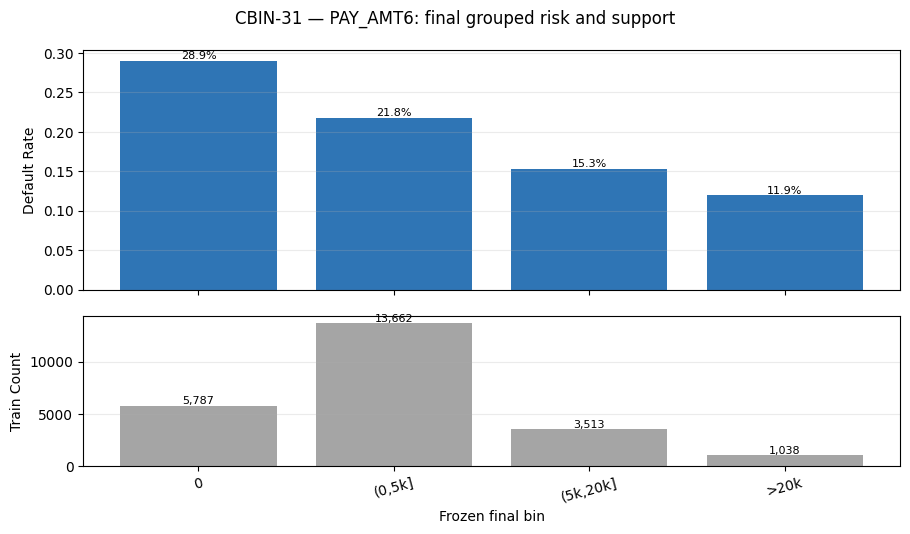

In [45]:
run_final("PAY_AMT6","CBIN-31")


## CBIN-32 — current_utilization Final Binning

- **Final grouping:** `0 / (0,0.2] / (0.2,0.6] / (0.6,1] / >1`
- **Human-approved rationale:** Common 20%/60%/100% mathematical regions; zero remains special.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},2080,0.086667,1564,516,0.248077,0.083677,0.097193,-0.149743,0.002024
1,B02,"(0,0.2]","(0,0.20]",8507,0.354458,7108,1399,0.164453,0.380290,0.263515,0.366825,0.042836
2,B03,"(0.2,0.6]","(0.20,0.60]",4716,0.196500,3671,1045,0.221586,0.196405,0.196836,-0.002191,0.000001
3,B04,"(0.6,1]","(0.60,1]",7012,0.292167,5183,1829,0.260839,0.277299,0.344509,-0.217024,0.014586
4,B05,>1,"(1,+∞)",1685,0.070208,1165,520,0.308605,0.062329,0.097947,-0.451991,0.016099


current_utilization — Final grouped total IV: 0.075545965143
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


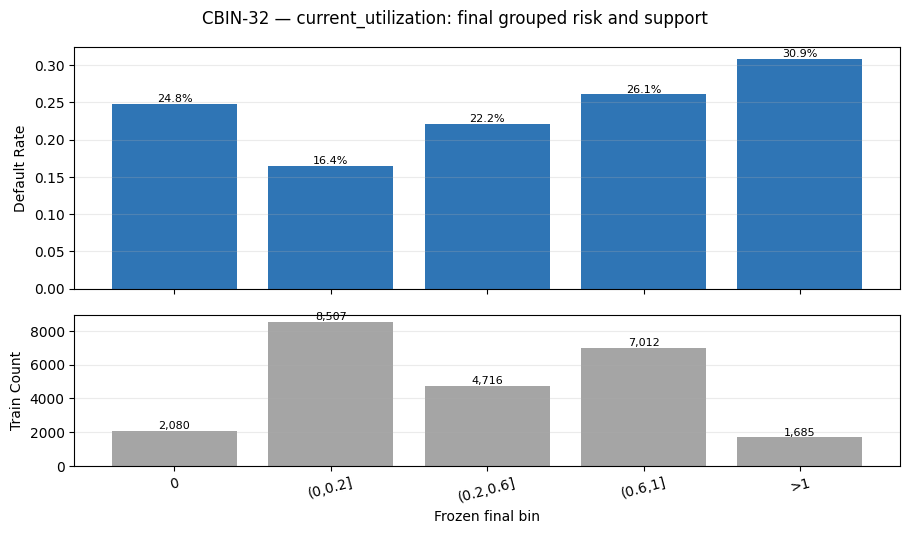

In [46]:
run_final("current_utilization","CBIN-32")


## CBIN-33 — avg_utilization Final Binning

- **Final grouping:** `same five-bin utilization rule`
- **Human-approved rationale:** Common 20%/60%/100% rule; extra 80% split rejected.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},771,0.032125,495,276,0.357977,0.026483,0.051987,-0.674482,0.017202
1,B02,"(0,0.2]","(0,0.20]",10021,0.417542,8372,1649,0.164554,0.447916,0.310605,0.366085,0.050268
2,B03,"(0.2,0.6]","(0.20,0.60]",5820,0.242500,4612,1208,0.207560,0.246750,0.227538,0.081057,0.001557
3,B04,"(0.6,1]","(0.60,1]",6880,0.286667,4882,1998,0.290407,0.261195,0.376342,-0.365230,0.042055
4,B05,>1,"(1,+∞)",508,0.021167,330,178,0.350394,0.017656,0.033528,-0.641330,0.010179


avg_utilization — Final grouped total IV: 0.121261375406
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


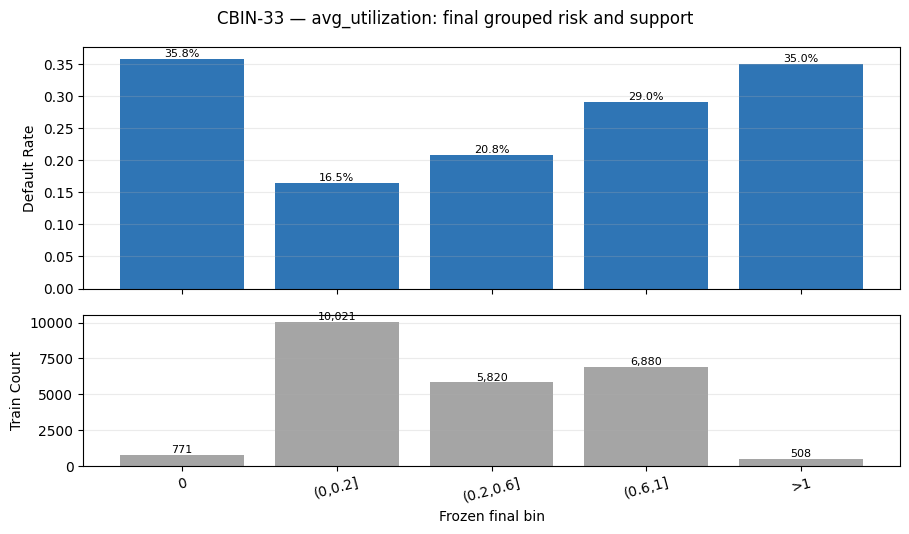

In [47]:
run_final("avg_utilization","CBIN-33")


## CBIN-34 — max_utilization Final Binning

- **Final grouping:** `same five-bin utilization rule`
- **Human-approved rationale:** Common 20%/60%/100% rule; values above 1 retained.
- **Observed final pattern:** Reported below from actual Train grouped rates/WOE; imperfections are retained without re-binning.
- **Stage 4.4 note:** Variable selection and redundancy review are deferred; no conclusion is made here.


,Final Bin ID,Display Label,Formal Numeric Definition,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,B01,0,{0},771,0.032125,495,276,0.357977,0.026483,0.051987,-0.674482,0.017202
1,B02,"(0,0.2]","(0,0.20]",8269,0.344542,6848,1421,0.171847,0.366380,0.267659,0.313957,0.030994
2,B03,"(0.2,0.6]","(0.20,0.60]",5018,0.209083,4058,960,0.191311,0.217110,0.180825,0.182874,0.006636
3,B04,"(0.6,1]","(0.60,1]",6813,0.283875,5113,1700,0.249523,0.273554,0.320211,-0.157481,0.007348
4,B05,>1,"(1,+∞)",3129,0.130375,2177,952,0.304251,0.116473,0.179318,-0.431501,0.027118


max_utilization — Final grouped total IV: 0.089296728682
Observed final pattern: ordered broad behavior recorded without forced monotonicity
Stage 4.4 note: selection/redundancy review is deferred; no inclusion conclusion.


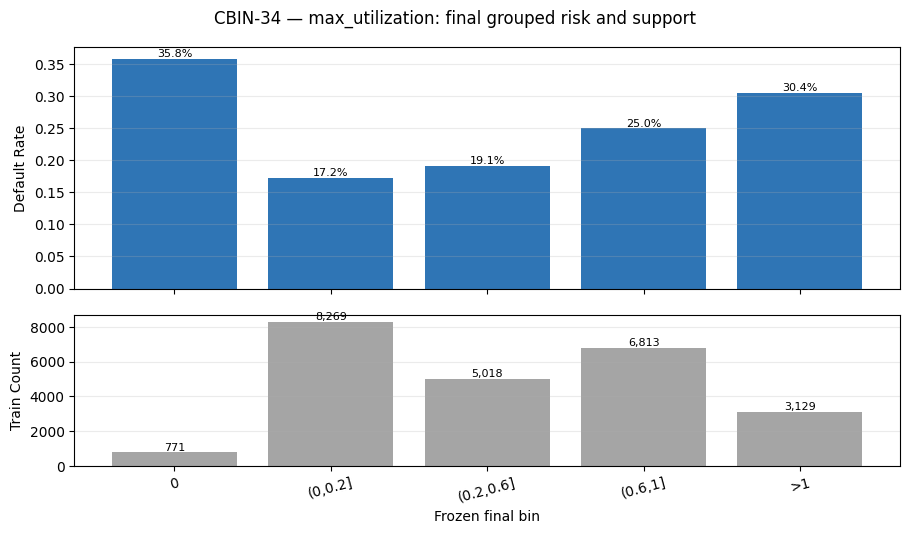

In [48]:
run_final("max_utilization","CBIN-34")


## 47. Diagnostic pre-bin → final IV comparison

Fixed 17-variable order; diagnostic only — no variable-selection or re-binning decision. IV loss does not reopen frozen bins.


In [49]:
iv_comparison=pd.DataFrame({"Variable":CONTINUOUS_VARIABLES,"Stage 4.3A pre-bin IV":[prebin_iv_totals[v] for v in CONTINUOUS_VARIABLES],"Stage 4.3B final grouped IV":[final_iv_totals[v] for v in CONTINUOUS_VARIABLES]}); iv_comparison["Absolute IV difference"]=(iv_comparison["Stage 4.3A pre-bin IV"]-iv_comparison["Stage 4.3B final grouped IV"]).abs(); iv_comparison["Retention ratio"]=iv_comparison["Stage 4.3B final grouped IV"]/iv_comparison["Stage 4.3A pre-bin IV"]; display(iv_comparison); print("diagnostic only — no variable-selection or re-binning decision")


,Variable,Stage 4.3A pre-bin IV,Stage 4.3B final grouped IV,Absolute IV difference,Retention ratio
0,AGE,0.023245,0.020429,0.002816,0.878853
1,LIMIT_BAL,0.201675,0.190445,0.011231,0.944314
2,BILL_AMT1,0.024475,0.015031,0.009445,0.614109
3,BILL_AMT2,0.022333,0.013564,0.008769,0.607348
4,BILL_AMT3,0.017565,0.011576,0.005990,0.658997
5,BILL_AMT4,0.023340,0.013016,0.010323,0.557693
6,BILL_AMT5,0.028634,0.016778,0.011856,0.585943
7,BILL_AMT6,0.029269,0.015700,0.013569,0.536416
8,PAY_AMT1,0.189100,0.175538,0.013562,0.928279
9,PAY_AMT2,0.161170,0.151114,0.010056,0.937605


diagnostic only — no variable-selection or re-binning decision


## 48. Human Checkpoint Decision Record and rejected alternatives

- Group 1: AGE `<=25 / 26–35 / 36–49 / 50+`; descriptive labels only. LIMIT_BAL freezes `30k / 140k / 240k`; additional 150k/250k robustness testing was explicitly declined.
- Group 2: BILL_AMT1–6 share `Negative / Zero / 0–10k / 10–40k / >40k`. Rejected: six variable-specific quantile systems, sample-specific boundaries such as ~8,541/~44,843, and an extra bin chasing the ~3k–6k dip.
- Group 3: PAY_AMT1–6 share `0 / 0–5k / 5–20k / >20k`. Rejected finer `0 / 0–2k / 2–5k / 5–10k / >10k` as too fragmented relative to Default Rate differences.
- Group 4: all utilization measures share `0 / 0–20% / 20–60% / 60–100% / >100%`. Extra ~80% split rejected as not equally compelling across measures.

These are frozen Human decisions, not results of an optimization performed here.


## 49. Final integrity and Stage 4.3 completion boundary

This closes Codex implementation only. It does not claim Reviewer PASS, create a milestone commit, or begin Stage 4.4.


In [50]:
assert list(final_tables)==CONTINUOUS_VARIABLES and len(final_tables)==17 and len(final_iv_totals)==17 and len(FINAL_BIN_COLUMNS)==17
assert all(int(t.Count.sum())==24000 and int(t.Good.sum())==18691 and int(t.Bad.sum())==5309 for t in final_tables.values())
assert all((t.Good>0).all() and (t.Bad>0).all() for t in final_tables.values())
assert all(np.isfinite(t[["WOE","IV Contribution"]]).all().all() for t in final_tables.values()) and all(np.isfinite(v) for v in final_iv_totals.values()) and not SMOOTHING_USED
assert figure_ids==[f"CBIN-{i:02d}" for i in range(1,35)] and len(set(figure_ids))==34
assert TEST_SEAL_STATUS.startswith("SEALED") and train_work[ID_COL].equals(phase_b_ids_before) and train_work[TARGET].equals(phase_b_target_before)
pd.testing.assert_frame_equal(train_work[CONTINUOUS_VARIABLES],phase_b_sources_before,check_exact=True)
FINAL_BIN_REDESIGN=False; CUTPOINT_SEARCH=False; IV_AUC_KS_OPTIMIZATION=False; TEST_RISK_ANALYSIS=False; VARIABLE_SELECTION=False; VIF=False; MODELING=False; KFOLD=False
assert not any([FINAL_BIN_REDESIGN,CUTPOINT_SEARCH,IV_AUC_KS_OPTIMIZATION,TEST_RISK_ANALYSIS,VARIABLE_SELECTION,VIF,MODELING,KFOLD])
final_iv_summary=pd.DataFrame({"Variable":CONTINUOUS_VARIABLES,"Final grouped total IV":[final_iv_totals[v] for v in CONTINUOUS_VARIABLES]}); display(final_iv_summary)
display(pd.DataFrame({"Result":["PASS — exactly 17 frozen mapping columns/tables","PASS — 24,000 / 18,691 / 5,309 for every table","PASS — all bins Good>0 and Bad>0","PASS — all WOE/IV finite; no NaN/inf","PASS — no smoothing","PASS — CBIN-01 through CBIN-34 unique","PASS — Holdout remained deleted/sealed","PASS — no redesign/search/selection/modeling/Stage 4.4","AWAITING — final Stage 4.3 Reviewer"]},index=["Mappings/tables","Reconciliation","Zero events","Finite metrics","Smoothing","Figures","Holdout","Scope","Next gate"]))
print("Stage 4.3B implementation complete — awaiting final Stage 4.3 Reviewer validation.")


,Variable,Final grouped total IV
0,AGE,0.020429
1,LIMIT_BAL,0.190445
2,BILL_AMT1,0.015031
3,BILL_AMT2,0.013564
4,BILL_AMT3,0.011576
5,BILL_AMT4,0.013016
6,BILL_AMT5,0.016778
7,BILL_AMT6,0.015700
8,PAY_AMT1,0.175538
9,PAY_AMT2,0.151114


,Result
Mappings/tables,PASS — exactly 17 frozen mapping columns/tables
Reconciliation,"PASS — 24,000 / 18,691 / 5,309 for every table"
Zero events,PASS — all bins Good>0 and Bad>0
Finite metrics,PASS — all WOE/IV finite; no NaN/inf
Smoothing,PASS — no smoothing
Figures,PASS — CBIN-01 through CBIN-34 unique
Holdout,PASS — Holdout remained deleted/sealed
Scope,PASS — no redesign/search/selection/modeling/S...
Next gate,AWAITING — final Stage 4.3 Reviewer


Stage 4.3B implementation complete — awaiting final Stage 4.3 Reviewer validation.
